# LithoAI 2.0 — Semiconductor Manufacturing Defect Prediction

This notebook presents a research investigation of machine-learning-based prediction of defective observations in the UCI SECOM semiconductor manufacturing dataset. It includes dataset quality checks, grouped validation, threshold selection, missing-data robustness, chronological generalisation, sensor-distribution analysis and feature importance.

**Execution status:** this saved copy was run from top to bottom in a fresh runtime. All 63 code cells have sequential execution counts and saved outputs, with no saved Python exceptions. A date-parsing warning and a scikit-learn warning for features entirely missing in an early temporal training window may appear; both were non-fatal in this run.

**Reporting note:** the notebook contains an initial exploratory grouped-CV benchmark and a later primary evaluation using a different model configuration. The exploratory scores are labelled separately below. The Abstract and Section 9 report the primary evaluation, which is also used for nested threshold evaluation and the missingness experiments.

## Abstract

Semiconductor manufacturing datasets are often high-dimensional, imbalanced and affected by incomplete sensor readings. This study evaluates machine-learning approaches for identifying defective observations in the UCI SECOM semiconductor manufacturing dataset, which contains 1,567 observations and 590 sensor features. Logistic Regression, Random Forest and HistGradientBoosting were assessed using timestamp-grouped cross-validation. Nested grouped validation was then used to select decision thresholds using an illustrative 80% recall target, while additional experiments examined artificial sensor-data loss, chronological generalisation, sensor-distribution changes, grouped permutation importance and missingness indicators. In pooled grouped evaluation, Random Forest and HistGradientBoosting achieved average-precision scores of 0.1860 and 0.1916, respectively, compared with 0.1390 for Logistic Regression and an overall failure prevalence of 0.0664. Under nested threshold evaluation, HistGradientBoosting detected 82.69% of failures but flagged 58.01% of observations for inspection; Random Forest detected 76.92% while flagging 45.63%. Expanding-window performance varied substantially across later periods, indicating limited temporal generalisation. Additional missingness and sensor-distribution analyses further demonstrated that data availability and temporal changes require explicit consideration. The findings support the use of grouped and temporal validation when evaluating predictive monitoring methods, while showing that the tested models are not yet suitable for unvalidated production deployment.

**Keywords:** semiconductor manufacturing; defect prediction; class imbalance; sensor data; grouped cross-validation; temporal validation; missing-data robustness.


## 1. Dataset loading and timestamp preparation

In [1]:
import os
import urllib.request
import zipfile
import pandas as pd
import numpy as np

# Download original UCI SECOM dataset
url = "https://archive.ics.uci.edu/static/public/179/secom.zip"
zip_path = "/content/secom.zip"
extract_path = "/content/secom_dataset"

urllib.request.urlretrieve(url, zip_path)

# Extract dataset
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

# Locate original files
found = {}

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file in ["secom.data", "secom_labels.data"]:
            found[file] = os.path.join(root, file)

print("Files found:", found)

# Load original data
X = pd.read_csv(
    found["secom.data"],
    sep=r"\s+",
    header=None
)

labels = pd.read_csv(
    found["secom_labels.data"],
    sep=r"\s+",
    header=None
)

# Restore target
y = labels.iloc[:, 0]
y_binary = (y == 1).astype(int)

print("\nDataset shape:", X.shape)
print("Labels shape:", labels.shape)
print("\nOriginal label distribution:")
print(y.value_counts())
print("\nDefective wafers:", y_binary.sum())
print("Non-defective wafers:", (y_binary == 0).sum())
print("\nMissing values:", X.isna().sum().sum())

Files found: {'secom.data': '/content/secom_dataset/secom.data', 'secom_labels.data': '/content/secom_dataset/secom_labels.data'}

Dataset shape: (1567, 590)
Labels shape: (1567, 2)

Original label distribution:
0
-1    1463
 1     104
Name: count, dtype: int64

Defective wafers: 104
Non-defective wafers: 1463

Missing values: 41951


In [2]:
# Convert the original timestamp column into datetime format
timestamps = pd.to_datetime(
    labels.iloc[:, 1],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

print("Missing timestamps:", timestamps.isna().sum())
print("Earliest observation:", timestamps.min())
print("Latest observation:", timestamps.max())

print("\nObservations in chronological order:", timestamps.is_monotonic_increasing)
print("Unique timestamps:", timestamps.nunique())
print("Duplicate timestamps:", timestamps.duplicated().sum())

print("\nObservations per date:")
print(timestamps.dt.date.value_counts().sort_index())

groups = timestamps


Missing timestamps: 0
Earliest observation: 2008-07-19 11:55:00
Latest observation: 2008-10-17 06:07:00

Observations in chronological order: True
Unique timestamps: 1534
Duplicate timestamps: 33

Observations per date:
1
2008-07-19    12
2008-07-20     1
2008-07-21     2
2008-07-22     6
2008-07-23     2
              ..
2008-10-13    22
2008-10-14    16
2008-10-15    34
2008-10-16    19
2008-10-17     3
Name: count, Length: 86, dtype: int64


## 2. Dataset quality and exploratory analysis

In [3]:

# LITHOAI 2.0 — STEP 1: Dataset Integrity Checks

print("Duplicate rows:", X.duplicated().sum())

print("Duplicate timestamps:", timestamps.duplicated().sum())

print("\nLabel distribution:")
print(y.value_counts())

print("\nMissing values per sensor (top 10):")
print(X.isna().sum().sort_values(ascending=False).head(10))

print("\nFeature summary:")
print(X.describe().T[["mean", "std", "min", "max"]].head(10))

# Check chronological ordering
print("\nTimestamps chronologically sorted:",
      timestamps.is_monotonic_increasing)

# Verify binary target mapping
assert (y_binary == (y == 1).astype(int)).all()

print("\nAll integrity checks completed.")


Duplicate rows: 0
Duplicate timestamps: 33

Label distribution:
0
-1    1463
 1     104
Name: count, dtype: int64

Missing values per sensor (top 10):
292    1429
293    1429
158    1429
157    1429
492    1341
85     1341
358    1341
220    1341
244    1018
517    1018
dtype: int64

Feature summary:
          mean         std        min        max
0  3014.452896   73.621787  2743.2400  3356.3500
1  2495.850231   80.407705  2158.7500  2846.4400
2  2200.547318   29.513152  2060.6600  2315.2667
3  1396.376627  441.691640     0.0000  3715.0417
4     4.197013   56.355540     0.6815  1114.5366
5   100.000000    0.000000   100.0000   100.0000
6   101.112908    6.237214    82.1311   129.2522
7     0.121822    0.008961     0.0000     0.1286
8     1.462862    0.073897     1.1910     1.6564
9    -0.000841    0.015116    -0.0534     0.0749

Timestamps chronologically sorted: True

All integrity checks completed.


In [4]:

# LITHOAI 2.0 — STEP 2: Sensor Quality Analysis

# 1. Missingness percentage for every sensor
missing_pct = X.isna().mean() * 100

print("Missingness distribution across sensors:")
print(missing_pct.describe())

# 2. Categorise sensors by missingness
missing_categories = {
    "No missing values": (missing_pct == 0).sum(),
    "1–20% missing": ((missing_pct > 0) & (missing_pct <= 20)).sum(),
    "20–50% missing": ((missing_pct > 20) & (missing_pct <= 50)).sum(),
    "50–80% missing": ((missing_pct > 50) & (missing_pct <= 80)).sum(),
    "Above 80% missing": (missing_pct > 80).sum()
}

print("\nSensor missingness categories:")
for category, count in missing_categories.items():
    print(f"{category}: {count}")

# 3. Identify constant and entirely missing sensors
constant_features = X.columns[X.nunique(dropna=True) <= 1]
all_missing_features = X.columns[X.isna().all()]

print("\nConstant sensors:", len(constant_features))
print("Entirely missing sensors:", len(all_missing_features))
print("Constant sensor indices:", list(constant_features))

# 4. Inspect repeated timestamp groups
group_analysis = pd.DataFrame({
    "timestamp": timestamps,
    "target": y_binary
})

group_summary = group_analysis.groupby("timestamp").agg(
    observations=("target", "size"),
    defective_samples=("target", "sum")
)

print("\nRepeated timestamp groups:",
      int((group_summary["observations"] > 1).sum()))

print("Groups containing both target classes:",
      int(((group_summary["defective_samples"] > 0) &
           (group_summary["defective_samples"] <
            group_summary["observations"])).sum()))

# 5. Confirm overall defect prevalence
print("\nOverall defect prevalence:",
      round(y_binary.mean() * 100, 2), "%")


Missingness distribution across sensors:
count    590.000000
mean       4.537549
std       15.433986
min        0.000000
25%        0.127632
50%        0.382897
75%        0.574346
max       91.193363
dtype: float64

Sensor missingness categories:
No missing values: 52
1–20% missing: 506
20–50% missing: 4
50–80% missing: 20
Above 80% missing: 8

Constant sensors: 116
Entirely missing sensors: 0
Constant sensor indices: [5, 13, 42, 49, 52, 69, 97, 141, 149, 178, 179, 186, 189, 190, 191, 192, 193, 194, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 240, 241, 242, 243, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 276, 284, 313, 314, 315, 322, 325, 326, 327, 328, 329, 330, 364, 369, 370, 371, 372, 373, 374, 375, 378, 379, 380, 381, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 414, 422, 449, 450, 451, 458, 461, 462, 463, 464, 465, 466, 481, 498, 501, 502, 503, 504, 505, 506, 507, 508, 509, 512, 513, 514, 515, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538]

Rep

In [5]:

# LITHOAI 2.0 — STEP 2: Feature Variability Audit

# Number of distinct observed values per sensor
unique_counts = X.nunique(dropna=True)

# Sensors with zero or one observed value
constant_sensors = unique_counts[unique_counts <= 1]

# Sensors with at least two distinct observed values
variable_sensors = unique_counts[unique_counts > 1]

# Missingness per sensor
missing_pct = X.isna().mean() * 100

print("Total sensors:", X.shape[1])
print("Constant or single-value sensors:", len(constant_sensors))
print("Variable sensors:", len(variable_sensors))
print("Sensors with >80% missingness:", (missing_pct > 80).sum())
print("Sensors with >50% missingness:", (missing_pct > 50).sum())

print("\nConstant sensor examples:")
print(constant_sensors.head(20))

print("\nVariable sensor count:", len(variable_sensors))

# Preserve raw data; do not drop columns here.


Total sensors: 590
Constant or single-value sensors: 116
Variable sensors: 474
Sensors with >80% missingness: 8
Sensors with >50% missingness: 28

Constant sensor examples:
5      1
13     1
42     1
49     1
52     1
69     1
97     1
141    1
149    1
178    1
179    1
186    1
189    1
190    1
191    1
192    1
193    1
194    1
226    1
229    1
dtype: int64

Variable sensor count: 474


In [6]:

# LITHOAI 2.0 — STEP 3: Preprocessing Pipeline Check

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier

preprocessing_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance_filter", VarianceThreshold(threshold=0.0)),
    ("classifier", RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Pipeline created successfully.")
print("\nPipeline stages:")
for name, step in preprocessing_pipeline.steps:
    print(f"{name}: {step}")




Pipeline created successfully.

Pipeline stages:
imputer: SimpleImputer(strategy='median')
variance_filter: VarianceThreshold()
classifier: RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=2,
                       n_estimators=500, n_jobs=-1, random_state=42)


### Exploratory grouped benchmark — alternative model configuration

The next grouped-CV block is an exploratory configuration check. It uses a different pipeline from the primary evaluation in Section 4 (including a 500-tree Random Forest and a 150-iteration HistGradientBoosting configuration). Its pooled AP scores — 0.1926 for Random Forest and 0.1880 for HistGradientBoosting — are retained as a separate experiment and must not be mixed with the primary results.

The primary model comparison is defined again in Section 4, using the configurations that are carried into nested threshold evaluation and the later robustness experiments. Its pooled OOF AP scores are 0.1390 for Logistic Regression, 0.1860 for Random Forest and 0.1916 for HistGradientBoosting. These are the headline results reported in the Abstract and Section 9.

In [7]:

# LITHOAI 2.0 — STEP 4: Grouped Cross-Validation Setup

from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_summary = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y_binary, groups=groups), start=1
):
    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])

    overlap = train_groups.intersection(test_groups)

    fold_summary.append({
        "Fold": fold,
        "Train samples": len(train_idx),
        "Test samples": len(test_idx),
        "Train defects": int(y_binary.iloc[train_idx].sum()),
        "Test defects": int(y_binary.iloc[test_idx].sum()),
        "Group overlap": len(overlap)
    })

    assert len(overlap) == 0, "Timestamp leakage detected!"

import pandas as pd
fold_summary = pd.DataFrame(fold_summary)

print(fold_summary.to_string(index=False))
print("\nTotal test observations:",
      fold_summary["Test samples"].sum())
print("Total test defects:",
      fold_summary["Test defects"].sum())
print("\nGrouped split verification passed.")



 Fold  Train samples  Test samples  Train defects  Test defects  Group overlap
    1           1253           314             84            20              0
    2           1253           314             86            18              0
    3           1252           315             80            24              0
    4           1258           309             88            16              0
    5           1252           315             78            26              0

Total test observations: 1567
Total test defects: 104

Grouped split verification passed.


In [8]:

# LITHOAI 2.0 — STEP 5: Grouped OOF Model Comparison

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd

models = {

"Logistic Regression": Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", __import__(
        "sklearn.preprocessing",
        fromlist=["StandardScaler"]
    ).StandardScaler()),
    ("variance_filter", VarianceThreshold()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=10000,
        solver="lbfgs",
        random_state=42
    ))
]),


    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance_filter", VarianceThreshold()),
        ("classifier", RandomForestClassifier(
            n_estimators=500,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance_filter", VarianceThreshold()),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.08,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=42
        ))
    ])
}

oof_predictions = {
    name: np.full(len(X), np.nan)
    for name in models
}

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y_binary, groups=groups), start=1
):
    print(f"\nRunning fold {fold}/5")

    for name, model in models.items():
        fitted_model = clone(model)

        fitted_model.fit(
            X.iloc[train_idx],
            y_binary.iloc[train_idx]
        )

        probabilities = fitted_model.predict_proba(
            X.iloc[test_idx]
        )[:, 1]

        oof_predictions[name][test_idx] = probabilities

        print(f"{name}: completed")

# Verify every observation received one prediction
for name, predictions in oof_predictions.items():
    assert np.isfinite(predictions).all(), (
        f"Missing predictions for {name}"
    )

# Calculate pooled out-of-fold PR-AUC
comparison = []

for name, predictions in oof_predictions.items():
    pr_auc = average_precision_score(
        y_binary,
        predictions
    )

    comparison.append({
        "Model": name,
        "Pooled OOF PR-AUC": pr_auc
    })

comparison = pd.DataFrame(comparison).sort_values(
    "Pooled OOF PR-AUC",
    ascending=False
)

print("\nFINAL MODEL COMPARISON")
print(comparison.to_string(index=False))



Running fold 1/5
Logistic Regression: completed
Random Forest: completed
HistGradientBoosting: completed

Running fold 2/5
Logistic Regression: completed
Random Forest: completed
HistGradientBoosting: completed

Running fold 3/5
Logistic Regression: completed
Random Forest: completed
HistGradientBoosting: completed

Running fold 4/5
Logistic Regression: completed
Random Forest: completed
HistGradientBoosting: completed

Running fold 5/5
Logistic Regression: completed
Random Forest: completed
HistGradientBoosting: completed

FINAL MODEL COMPARISON
               Model  Pooled OOF PR-AUC
       Random Forest           0.192593
HistGradientBoosting           0.187956
 Logistic Regression           0.138951


In [9]:

# LITHOAI 2.0 — STEP 6: Fold-Level PR-AUC Stability

from sklearn.metrics import average_precision_score
import pandas as pd

fold_results = []

for fold, (_, test_idx) in enumerate(
    cv.split(X, y_binary, groups=groups), start=1
):
    for model_name, predictions in oof_predictions.items():

        fold_score = average_precision_score(
            y_binary.iloc[test_idx],
            predictions[test_idx]
        )

        fold_results.append({
            "Fold": fold,
            "Model": model_name,
            "PR-AUC": fold_score
        })

fold_results = pd.DataFrame(fold_results)

print("PR-AUC BY FOLD")
print(fold_results.pivot(
    index="Fold",
    columns="Model",
    values="PR-AUC"
).round(4))

print("\nMEAN AND STANDARD DEVIATION")
print(fold_results.groupby("Model")["PR-AUC"].agg(
    ["mean", "std", "min", "max"]
).round(4))


PR-AUC BY FOLD
Model  HistGradientBoosting  Logistic Regression  Random Forest
Fold                                                           
1                    0.2209               0.1567         0.2436
2                    0.3067               0.1567         0.3468
3                    0.1539               0.1536         0.1314
4                    0.0946               0.1176         0.1238
5                    0.3204               0.1994         0.3383

MEAN AND STANDARD DEVIATION
                        mean     std     min     max
Model                                               
HistGradientBoosting  0.2193  0.0971  0.0946  0.3204
Logistic Regression   0.1568  0.0290  0.1176  0.1994
Random Forest         0.2368  0.1076  0.1238  0.3468


In [10]:

# LITHOAI 2.0 — STEP 7: Random Forest Operating Points

from sklearn.metrics import precision_score, recall_score
import pandas as pd
import numpy as np

rf_probs = oof_predictions["Random Forest"]
y_true = y_binary.to_numpy()

thresholds = [0.01, 0.02, 0.03, 0.05, 0.07, 0.10, 0.15, 0.20]

results = []

for threshold in thresholds:

    predictions = (rf_probs >= threshold).astype(int)

    tp = int(((predictions == 1) & (y_true == 1)).sum())
    fp = int(((predictions == 1) & (y_true == 0)).sum())
    tn = int(((predictions == 0) & (y_true == 0)).sum())
    fn = int(((predictions == 0) & (y_true == 1)).sum())

    results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "Inspection rate": predictions.mean()
    })

operating_table = pd.DataFrame(results)

print(operating_table.round(4).to_string(index=False))


 Threshold  TP   FP   TN  FN  Precision  Recall  Inspection rate
      0.01 104 1463    0   0     0.0664  1.0000           1.0000
      0.02 104 1435   28   0     0.0676  1.0000           0.9821
      0.03 104 1346  117   0     0.0717  1.0000           0.9253
      0.05  97  965  498   7     0.0913  0.9327           0.6777
      0.07  77  597  866  27     0.1142  0.7404           0.4301
      0.10  56  265 1198  48     0.1745  0.5385           0.2049
      0.15  18   67 1396  86     0.2118  0.1731           0.0542
      0.20   7   17 1446  97     0.2917  0.0673           0.0153


In [11]:
# Examine missing values in individual sensor features

missing_per_feature = X.isna().sum()

print("Features with missing values:",
      (missing_per_feature > 0).sum())

print("\nFeatures with more than 50% missing data:",
      (missing_per_feature > len(X) * 0.5).sum())

print("\n10 features with the most missing values:")
print(missing_per_feature.sort_values(ascending=False).head(10))

print("\nLabel values:")
print(labels.head())

Features with missing values: 538

Features with more than 50% missing data: 28

10 features with the most missing values:
292    1429
293    1429
158    1429
157    1429
492    1341
85     1341
358    1341
220    1341
244    1018
517    1018
dtype: int64

Label values:
   0                    1
0 -1  19/07/2008 11:55:00
1 -1  19/07/2008 12:32:00
2  1  19/07/2008 13:17:00
3 -1  19/07/2008 14:43:00
4 -1  19/07/2008 15:22:00


In [12]:
# Missing data analysis

missing_per_feature = X.isna().sum()

missing_percentage = (missing_per_feature / len(X)) * 100

missing_summary = pd.DataFrame({
    "Missing_Count": missing_per_feature,
    "Missing_Percentage": missing_percentage
})

print("Features with 0% missing:",
      (missing_percentage == 0).sum())

print("Features with 1-25% missing:",
      ((missing_percentage > 0) & (missing_percentage <= 25)).sum())

print("Features with 25-50% missing:",
      ((missing_percentage > 25) & (missing_percentage <= 50)).sum())

print("Features with 50-75% missing:",
      ((missing_percentage > 50) & (missing_percentage <= 75)).sum())

print("Features with 75-100% missing:",
      (missing_percentage > 75).sum())

print("\nTimestamp range:")
timestamps = pd.to_datetime(
    labels.iloc[:, 1],
    dayfirst=True
)

print(timestamps.min())
print(timestamps.max())

Features with 0% missing: 52
Features with 1-25% missing: 506
Features with 25-50% missing: 4
Features with 50-75% missing: 20
Features with 75-100% missing: 8

Timestamp range:
2008-07-19 11:55:00
2008-10-17 06:07:00


In [13]:
# Combine sensor data, labels and timestamps

df = X.copy()

df["label"] = y.values
df["timestamp"] = timestamps.values

# Check chronological ordering
print("Are observations chronologically sorted?",
      df["timestamp"].is_monotonic_increasing)

print("\nNumber of duplicate timestamps:",
      df["timestamp"].duplicated().sum())

# Group observations by month
df["month"] = df["timestamp"].dt.to_period("M")

monthly_results = df.groupby("month")["label"].agg(
    Total="count",
    Failures=lambda x: (x == 1).sum(),
    Passes=lambda x: (x == -1).sum()
)

print("\nMonthly pass/fail distribution:")
print(monthly_results)

# Missing data per observation
row_missing = X.isna().sum(axis=1)

print("\nAverage missing sensor readings per observation:",
      row_missing.mean())

print("Maximum missing sensor readings in one observation:",
      row_missing.max())

Are observations chronologically sorted? True

Number of duplicate timestamps: 33

Monthly pass/fail distribution:
         Total  Failures  Passes
month                           
2008-07     63        14      49
2008-08    555        51     504
2008-09    590        17     573
2008-10    359        22     337

Average missing sensor readings per observation: 26.771537970644545
Maximum missing sensor readings in one observation: 152


In [14]:
# 1. Calculate monthly failure rates

monthly_results["Failure_Rate_%"] = (
    monthly_results["Failures"] /
    monthly_results["Total"] * 100
)

print("Monthly failure rates:")
print(monthly_results.round(2))


# 2. Investigate duplicate timestamps

duplicate_rows = df[
    df["timestamp"].duplicated(keep=False)
]

print("\nRows with duplicate timestamps:",
      len(duplicate_rows))

print("\nDo duplicate timestamps have conflicting labels?")

print(
    duplicate_rows.groupby("timestamp")["label"]
    .nunique()
    .value_counts()
)


# 3. Check class distribution in chronological sections

n = len(df)

first = df.iloc[:int(n * 0.70)]
middle = df.iloc[int(n * 0.70):int(n * 0.85)]
last = df.iloc[int(n * 0.85):]

for name, section in [
    ("First 70%", first),
    ("Next 15%", middle),
    ("Final 15%", last)
]:
    print("\n", name)
    print("Total:", len(section))
    print("Failures:", (section["label"] == 1).sum())
    print("Passes:", (section["label"] == -1).sum())

Monthly failure rates:
         Total  Failures  Passes  Failure_Rate_%
month                                           
2008-07     63        14      49           22.22
2008-08    555        51     504            9.19
2008-09    590        17     573            2.88
2008-10    359        22     337            6.13

Rows with duplicate timestamps: 65

Do duplicate timestamps have conflicting labels?
label
1    29
2     3
Name: count, dtype: int64

 First 70%
Total: 1096
Failures: 78
Passes: 1018

 Next 15%
Total: 235
Failures: 17
Passes: 218

 Final 15%
Total: 236
Failures: 9
Passes: 227


In [15]:
# Find timestamps associated with conflicting labels

label_counts = (
    duplicate_rows.groupby("timestamp")["label"]
    .nunique()
)

conflicting_timestamps = label_counts[
    label_counts > 1
].index

print("Conflicting timestamps:")
print(conflicting_timestamps)

print("\nDetailed conflicting observations:")

for t in conflicting_timestamps:
    print("\nTimestamp:", t)

    display(
        df[df["timestamp"] == t][
            ["label", "timestamp"]
        ]
    )

Conflicting timestamps:
DatetimeIndex(['2008-08-05 07:12:00', '2008-08-31 10:59:00',
               '2008-10-05 00:33:00'],
              dtype='datetime64[ns]', name='timestamp', freq=None)

Detailed conflicting observations:

Timestamp: 2008-08-05 07:12:00


,label,timestamp
114,-1,2008-08-05 07:12:00
115,1,2008-08-05 07:12:00



Timestamp: 2008-08-31 10:59:00


,label,timestamp
605,1,2008-08-31 10:59:00
606,-1,2008-08-31 10:59:00



Timestamp: 2008-10-05 00:33:00


,label,timestamp
1303,1,2008-10-05 00:33:00
1304,-1,2008-10-05 00:33:00


In [16]:
# Compare sensor readings for conflicting timestamps

for t in conflicting_timestamps:

    indices = df.index[df["timestamp"] == t].tolist()

    row1 = X.loc[indices[0]]
    row2 = X.loc[indices[1]]

    # Compare sensor readings, accounting for NaN values
    same_readings = np.array_equal(
        row1.to_numpy(),
        row2.to_numpy(),
        equal_nan=True
    )

    different_features = (
        (row1 != row2) &
        ~(row1.isna() & row2.isna())
    ).sum()

    print("\nTimestamp:", t)
    print("Observation indices:", indices)
    print("Identical sensor readings:", same_readings)
    print("Number of different sensor features:",
          different_features)


Timestamp: 2008-08-05 07:12:00
Observation indices: [114, 115]
Identical sensor readings: False
Number of different sensor features: 427

Timestamp: 2008-08-31 10:59:00
Observation indices: [605, 606]
Identical sensor readings: False
Number of different sensor features: 429

Timestamp: 2008-10-05 00:33:00
Observation indices: [1303, 1304]
Identical sensor readings: False
Number of different sensor features: 439


## 3. Preliminary model development and validation

In [17]:
from sklearn.model_selection import StratifiedGroupKFold

# Convert labels:
# -1 (Pass) -> 0
#  1 (Fail) -> 1

y_binary = (y == 1).astype(int)

# Group observations by timestamp
groups = timestamps

# Create 5 stratified group folds
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use the first fold for our initial experiment
train_idx, test_idx = next(
    sgkf.split(X, y_binary, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y_binary.iloc[train_idx]
y_test = y_binary.iloc[test_idx]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nTraining failure percentage:",
      y_train.mean() * 100)

print("Testing failure percentage:",
      y_test.mean() * 100)

Training observations: 1253
Testing observations: 314

Training class distribution:
0
0    1169
1      84
Name: count, dtype: int64

Testing class distribution:
0
0    294
1     20
Name: count, dtype: int64

Training failure percentage: 6.70391061452514
Testing failure percentage: 6.369426751592357


In [18]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    average_precision_score
)

# Step 1: Select features using training data only
keep_features = X_train.columns[
    X_train.isna().mean() <= 0.50
]

X_train_clean = X_train[keep_features]
X_test_clean = X_test[keep_features]

print("Original features:", X_train.shape[1])
print("Features retained:", len(keep_features))
print("Features removed:", X_train.shape[1] - len(keep_features))

# Step 2: Create our Logistic Regression pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

# Step 3: Train the model
model.fit(X_train_clean, y_train)

# Step 4: Make predictions
y_pred = model.predict(X_test_clean)
y_prob = model.predict_proba(X_test_clean)[:, 1]

# Step 5: Evaluate performance
print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Pass", "Fail"],
    zero_division=0
))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred))

print("PR-AUC (Average Precision):",
      average_precision_score(y_test, y_prob))

Original features: 590
Features retained: 562
Features removed: 28

CONFUSION MATRIX:
[[265  29]
 [ 14   6]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        Pass       0.95      0.90      0.92       294
        Fail       0.17      0.30      0.22        20

    accuracy                           0.86       314
   macro avg       0.56      0.60      0.57       314
weighted avg       0.90      0.86      0.88       314

Balanced Accuracy: 0.6006802721088436
PR-AUC (Average Precision): 0.15045727953192714


In [19]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    average_precision_score
)

# Create Random Forest pipeline
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_model.fit(X_train_clean, y_train)

# Predict
rf_pred = rf_model.predict(X_test_clean)
rf_prob = rf_model.predict_proba(X_test_clean)[:, 1]

# Evaluate
print("RANDOM FOREST RESULTS")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Pass", "Fail"],
    zero_division=0
))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, rf_pred))

print("PR-AUC:",
      average_precision_score(y_test, rf_prob))

RANDOM FOREST RESULTS

Confusion Matrix:
[[294   0]
 [ 20   0]]

Classification Report:
              precision    recall  f1-score   support

        Pass       0.94      1.00      0.97       294
        Fail       0.00      0.00      0.00        20

    accuracy                           0.94       314
   macro avg       0.47      0.50      0.48       314
weighted avg       0.88      0.94      0.91       314

Balanced Accuracy: 0.5
PR-AUC: 0.21167945155075057


In [20]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import numpy as np

# Create a validation split from training data
groups_train = groups.loc[X_train.index]

sgkf_val = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=21
)

sub_train_idx, val_idx = next(
    sgkf_val.split(X_train, y_train, groups_train)
)

X_subtrain = X_train.iloc[sub_train_idx]
X_val = X_train.iloc[val_idx]

y_subtrain = y_train.iloc[sub_train_idx]
y_val = y_train.iloc[val_idx]

# Use the same feature set selected earlier
X_subtrain = X_subtrain[keep_features]
X_val = X_val[keep_features]

# Train a fresh Random Forest on subtraining data
rf_validation = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

rf_validation.fit(X_subtrain, y_subtrain)

# Get validation probabilities
val_prob = rf_validation.predict_proba(X_val)[:, 1]

# Evaluate different probability thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val, val_prob
)

print("Validation observations:", len(X_val))
print("Validation failures:", y_val.sum())

print("\nPR-AUC:",
      average_precision_score(y_val, val_prob))

print("\nThreshold analysis:")

for threshold in [0.05, 0.10, 0.15, 0.20, 0.25,
                  0.30, 0.35, 0.40, 0.45, 0.50]:

    predictions = (val_prob >= threshold).astype(int)

    tp = ((predictions == 1) & (y_val.to_numpy() == 1)).sum()
    fp = ((predictions == 1) & (y_val.to_numpy() == 0)).sum()
    fn = ((predictions == 0) & (y_val.to_numpy() == 1)).sum()

    rec = tp / (tp + fn) if tp + fn else 0
    prec = tp / (tp + fp) if tp + fp else 0

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {prec:.3f} | "
        f"Recall: {rec:.3f} | "
        f"Detected failures: {tp}"
    )

Validation observations: 251
Validation failures: 24

PR-AUC: 0.3118244151776217

Threshold analysis:
Threshold: 0.05 | Precision: 0.126 | Recall: 0.917 | Detected failures: 22
Threshold: 0.10 | Precision: 0.262 | Recall: 0.458 | Detected failures: 11
Threshold: 0.15 | Precision: 0.500 | Recall: 0.167 | Detected failures: 4
Threshold: 0.20 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.25 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.30 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.35 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.40 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.45 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0
Threshold: 0.50 | Precision: 0.000 | Recall: 0.000 | Detected failures: 0


In [21]:
# Inspect predicted failure probabilities

print("Minimum probability:", val_prob.min())
print("Maximum probability:", val_prob.max())

print("\nProbability distribution:")
print(pd.Series(val_prob).describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

print("\nNumber of observations flagged:")

for threshold in [0.05, 0.10, 0.15, 0.20, 0.50]:
    flagged = (val_prob >= threshold).sum()

    print(
        f"Threshold {threshold:.2f}: "
        f"{flagged} observations"
    )

Minimum probability: 0.009703237410071942
Maximum probability: 0.19283433957761428

Probability distribution:
count    251.000000
mean       0.069611
std        0.033702
min        0.009703
25%        0.045266
50%        0.064325
75%        0.085960
90%        0.120161
95%        0.132607
99%        0.166661
max        0.192834
dtype: float64

Number of observations flagged:
Threshold 0.05: 175 observations
Threshold 0.10: 42 observations
Threshold 0.15: 8 observations
Threshold 0.20: 0 observations
Threshold 0.50: 0 observations


In [22]:
# Corrected Random Forest validation experiment

# Select features using subtraining data ONLY
valid_features = X_subtrain.columns[
    X_subtrain.isna().mean() <= 0.50
]

X_subtrain_corrected = X_subtrain[valid_features]
X_val_corrected = X_val[valid_features]

print("Features selected:", len(valid_features))

# Build model
rf_corrected = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_corrected.fit(
    X_subtrain_corrected,
    y_subtrain
)

# Predict probabilities
corrected_prob = rf_corrected.predict_proba(
    X_val_corrected
)[:, 1]

# Evaluate
print("\nCorrected validation PR-AUC:",
      average_precision_score(y_val, corrected_prob))

print("\nCorrected probability distribution:")
print(pd.Series(corrected_prob).describe())

print("\nThreshold analysis:")

for threshold in [0.05, 0.10, 0.15, 0.20, 0.25, 0.50]:

    pred = (corrected_prob >= threshold).astype(int)

    tp = ((pred == 1) & (y_val.to_numpy() == 1)).sum()
    fp = ((pred == 1) & (y_val.to_numpy() == 0)).sum()
    fn = ((pred == 0) & (y_val.to_numpy() == 1)).sum()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"Detected: {tp}"
    )

Features selected: 562

Corrected validation PR-AUC: 0.3118244151776217

Corrected probability distribution:
count    251.000000
mean       0.069611
std        0.033702
min        0.009703
25%        0.045266
50%        0.064325
75%        0.085960
max        0.192834
dtype: float64

Threshold analysis:
Threshold: 0.05 | Precision: 0.126 | Recall: 0.917 | Detected: 22
Threshold: 0.10 | Precision: 0.262 | Recall: 0.458 | Detected: 11
Threshold: 0.15 | Precision: 0.500 | Recall: 0.167 | Detected: 4
Threshold: 0.20 | Precision: 0.000 | Recall: 0.000 | Detected: 0
Threshold: 0.25 | Precision: 0.000 | Recall: 0.000 | Detected: 0
Threshold: 0.50 | Precision: 0.000 | Recall: 0.000 | Detected: 0


In [23]:
print(
    "Are both feature selections identical?",
    set(keep_features) == set(valid_features)
)

print(
    "Number of common features:",
    len(set(keep_features) & set(valid_features))
)

Are both feature selections identical? True
Number of common features: 562


In [24]:
# MISSING SENSOR DATA ROBUSTNESS EXPERIMENT

from sklearn.metrics import average_precision_score
import numpy as np
import pandas as pd

# Use the corrected validation features
X_robust = X_val_corrected.copy()

missing_levels = [0, 5, 10, 20, 30]

results = []

for level in missing_levels:

    # Create a reproducible copy
    X_test_missing = X_robust.copy()

    # Randomly hide additional sensor readings
    rng = np.random.default_rng(42)

    if level > 0:
        mask = rng.random(X_test_missing.shape) < (level / 100)

        X_test_missing = X_test_missing.mask(mask)

    # Predict using the same trained model
    probabilities = rf_corrected.predict_proba(
        X_test_missing
    )[:, 1]

    # Evaluate
    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    predictions = (probabilities >= 0.05).astype(int)

    tp = ((predictions == 1) &
          (y_val.to_numpy() == 1)).sum()

    fn = ((predictions == 0) &
          (y_val.to_numpy() == 1)).sum()

    recall = tp / (tp + fn) if tp + fn else 0

    results.append({
        "Additional Missing Data (%)": level,
        "PR-AUC": round(pr_auc, 4),
        "Failure Recall": round(recall, 4),
        "Detected Failures": int(tp)
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 Additional Missing Data (%)  PR-AUC  Failure Recall  Detected Failures
                           0  0.3118          0.9167                 22
                           5  0.2930          0.9583                 23
                          10  0.2764          0.9583                 23
                          20  0.2360          0.9583                 23
                          30  0.2120          1.0000                 24


In [25]:
from sklearn.metrics import confusion_matrix

print("MISSING DATA FALSE-ALARM ANALYSIS")

for level in [0, 5, 10, 20, 30]:

    X_test_missing = X_robust.copy()

    rng = np.random.default_rng(42)

    if level > 0:
        mask = rng.random(X_test_missing.shape) < (level / 100)
        X_test_missing = X_test_missing.mask(mask)

    probabilities = rf_corrected.predict_proba(
        X_test_missing
    )[:, 1]

    predictions = (probabilities >= 0.05).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    print(f"\nMissing data: {level}%")
    print("True positives:", tp)
    print("False positives:", fp)
    print("True negatives:", tn)
    print("False negatives:", fn)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))

MISSING DATA FALSE-ALARM ANALYSIS

Missing data: 0%
True positives: 22
False positives: 153
True negatives: 74
False negatives: 2
Precision: 0.1257
Recall: 0.9167

Missing data: 5%
True positives: 23
False positives: 162
True negatives: 65
False negatives: 1
Precision: 0.1243
Recall: 0.9583

Missing data: 10%
True positives: 23
False positives: 166
True negatives: 61
False negatives: 1
Precision: 0.1217
Recall: 0.9583

Missing data: 20%
True positives: 23
False positives: 176
True negatives: 51
False negatives: 1
Precision: 0.1156
Recall: 0.9583

Missing data: 30%
True positives: 24
False positives: 194
True negatives: 33
False negatives: 0
Precision: 0.1101
Recall: 1.0


In [26]:
print("INSPECTION BURDEN ANALYSIS")

total = len(y_val)

for level, tp, fp, tn, fn in [
    (0, 22, 153, 74, 2),
    (5, 23, 162, 65, 1),
    (10, 23, 166, 61, 1),
    (20, 23, 176, 51, 1),
    (30, 24, 194, 33, 0)
]:
    flagged = tp + fp
    inspection_rate = (flagged / total) * 100
    unnecessary_rate = (fp / flagged) * 100

    print(f"\nMissingness: {level}%")
    print(f"Observations flagged: {flagged}/{total}")
    print(f"Inspection rate: {inspection_rate:.2f}%")
    print(f"Unnecessary inspections: {unnecessary_rate:.2f}%")

INSPECTION BURDEN ANALYSIS

Missingness: 0%
Observations flagged: 175/251
Inspection rate: 69.72%
Unnecessary inspections: 87.43%

Missingness: 5%
Observations flagged: 185/251
Inspection rate: 73.71%
Unnecessary inspections: 87.57%

Missingness: 10%
Observations flagged: 189/251
Inspection rate: 75.30%
Unnecessary inspections: 87.83%

Missingness: 20%
Observations flagged: 199/251
Inspection rate: 79.28%
Unnecessary inspections: 88.44%

Missingness: 30%
Observations flagged: 218/251
Inspection rate: 86.85%
Unnecessary inspections: 88.99%


In [27]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score
)

levels = [0, 5, 10, 20, 30]
seeds = range(10)

repeated_results = []

for level in levels:
    for seed in seeds:

        X_missing = X_robust.copy()

        if level > 0:
            rng = np.random.default_rng(seed)
            mask = rng.random(X_missing.shape) < (level / 100)
            X_missing = X_missing.mask(mask)

        probabilities = rf_corrected.predict_proba(X_missing)[:, 1]
        predictions = (probabilities >= 0.05).astype(int)

        tp = ((y_val == 1) & (predictions == 1)).sum()
        fp = ((y_val == 0) & (predictions == 1)).sum()

        repeated_results.append({
            "Missingness": level,
            "Seed": seed,
            "PR_AUC": average_precision_score(y_val, probabilities),
            "Precision": precision_score(y_val, predictions, zero_division=0),
            "Recall": recall_score(y_val, predictions, zero_division=0),
            "Inspection_Rate": (tp + fp) / len(y_val)
        })

repeated_df = pd.DataFrame(repeated_results)

summary = repeated_df.groupby("Missingness").agg(
    PR_AUC_Mean=("PR_AUC", "mean"),
    PR_AUC_Std=("PR_AUC", "std"),
    Precision_Mean=("Precision", "mean"),
    Recall_Mean=("Recall", "mean"),
    Inspection_Rate_Mean=("Inspection_Rate", "mean")
)

print(summary.round(4))

             PR_AUC_Mean  PR_AUC_Std  Precision_Mean  Recall_Mean  \
Missingness                                                         
0                 0.3118      0.0000          0.1257       0.9167   
5                 0.3030      0.0317          0.1246       0.9292   
10                0.2956      0.0306          0.1232       0.9458   
20                0.2701      0.0438          0.1153       0.9667   
30                0.2642      0.0315          0.1069       0.9750   

             Inspection_Rate_Mean  
Missingness                        
0                          0.6972  
5                          0.7131  
10                         0.7343  
20                         0.8020  
30                         0.8721  


In [28]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.6.1


In [29]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

# 1. Logistic Regression
lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

lr_model.fit(X_subtrain_corrected, y_subtrain)

# 2. Existing Random Forest
# rf_corrected has already been trained on the same subtraining data.

# 3. HistGradientBoosting
hgb_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    class_weight="balanced",
    random_state=42
)

hgb_model.fit(X_subtrain_corrected, y_subtrain)

# Evaluate all three on the same validation observations
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_corrected,
    "HistGradientBoosting": hgb_model
}

comparison = []

for name, model in models.items():
    probabilities = model.predict_proba(X_val_corrected)[:, 1]

    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    comparison.append({
        "Model": name,
        "PR_AUC": pr_auc
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.sort_values(
    by="PR_AUC",
    ascending=False
).round(4))

                  Model  PR_AUC
1         Random Forest  0.3118
2  HistGradientBoosting  0.2131
0   Logistic Regression  0.1610


In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in np.arange(0.01, 0.51, 0.01):

    predictions = (val_prob >= threshold).astype(int)

    tp = ((y_val == 1) & (predictions == 1)).sum()
    fp = ((y_val == 0) & (predictions == 1)).sum()
    fn = ((y_val == 1) & (predictions == 0)).sum()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "Inspection_Rate": (tp + fp) / len(y_val),
        "False_Alarms": fp
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df[
    threshold_df["Recall"] >= 0.80
].round(4).to_string(index=False))

 Threshold  Precision  Recall     F1  Inspection_Rate  False_Alarms
      0.01     0.0960  1.0000 0.1752           0.9960           226
      0.02     0.0972  1.0000 0.1771           0.9841           223
      0.03     0.1043  1.0000 0.1890           0.9163           206
      0.04     0.1144  0.9583 0.2044           0.8008           178
      0.05     0.1257  0.9167 0.2211           0.6972           153
      0.06     0.1511  0.8750 0.2577           0.5538           118
      0.07     0.1869  0.8333 0.3053           0.4263            87


Preliminary observation: Increasing the classification threshold from 0.05 to 0.07 reduced the validation inspection rate from 69.72% to 42.63%, while recall decreased from 91.67% to 83.33%. Precision improved from 12.57% to 18.69%.

This suggests that threshold selection can substantially influence the balance between failure detection and inspection workload.

Important: 0.07 is a promising candidate, not our final chosen threshold. We selected it after looking at validation results, so we must use a separate final test set for an unbiased performance estimate.

In [31]:
from sklearn.metrics import confusion_matrix

thresholds = [0.05, 0.06, 0.07]
missing_levels = [0, 5, 10, 20, 30]

threshold_robustness = []

for level in missing_levels:

    X_missing = X_robust.copy()

    if level > 0:
        rng = np.random.default_rng(42)
        mask = rng.random(X_missing.shape) < (level / 100)
        X_missing = X_missing.mask(mask)

    probabilities = rf_corrected.predict_proba(X_missing)[:, 1]

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        threshold_robustness.append({
            "Missingness": level,
            "Threshold": threshold,
            "Precision": tp / (tp + fp) if tp + fp else 0,
            "Recall": tp / (tp + fn) if tp + fn else 0,
            "Inspection_Rate": (tp + fp) / len(y_val),
            "False_Alarms": fp
        })

robustness_df = pd.DataFrame(threshold_robustness)

print(robustness_df.round(4).to_string(index=False))

 Missingness  Threshold  Precision  Recall  Inspection_Rate  False_Alarms
           0       0.05     0.1257  0.9167           0.6972           153
           0       0.06     0.1511  0.8750           0.5538           118
           0       0.07     0.1869  0.8333           0.4263            87
           5       0.05     0.1243  0.9583           0.7371           162
           5       0.06     0.1438  0.8750           0.5817           125
           5       0.07     0.1802  0.8333           0.4422            91
          10       0.05     0.1217  0.9583           0.7530           166
          10       0.06     0.1355  0.8750           0.6175           134
          10       0.07     0.1736  0.8750           0.4821           100
          20       0.05     0.1156  0.9583           0.7928           176
          20       0.06     0.1250  0.9167           0.7012           154
          20       0.07     0.1458  0.8750           0.5737           123
          30       0.05     0.1101  1.

Across the evaluated missing-data conditions, increasing the classification threshold from 0.05 to 0.07 reduced the inspection rate. However, inspection burden continued to increase with additional missingness, even at the higher threshold. This indicates that threshold adjustment alone may not be sufficient to maintain inspection efficiency under degraded sensor availability.

In [32]:
print("Total observations:", len(X))
print("Unique timestamp groups:", groups.nunique())
print("Total features:", X.shape[1])
print("Failure observations:", (y == 1).sum())
print("Passing observations:", (y == -1).sum())

Total observations: 1567
Unique timestamp groups: 1534
Total features: 590
Failure observations: 104
Passing observations: 1463


## 4. Grouped cross-validation and nested threshold evaluation

In [33]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
import numpy as np
import pandas as pd

# Convert labels: pass = 0, fail = 1
y_binary = (y == 1).astype(int)

# Define models
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )),
        ("variance", VarianceThreshold()),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y_binary, groups=groups), start=1
):

    X_tr = X.iloc[train_idx]
    X_va = X.iloc[val_idx]

    y_tr = y_binary.iloc[train_idx]
    y_va = y_binary.iloc[val_idx]

    for name, model in models.items():

        fitted_model = clone(model)
        fitted_model.fit(X_tr, y_tr)

        probabilities = fitted_model.predict_proba(X_va)[:, 1]

        score = average_precision_score(y_va, probabilities)

        cv_results.append({
            "Fold": fold,
            "Model": name,
            "PR_AUC": score,
            "Validation_Failures": int(y_va.sum()),
            "Validation_Size": len(y_va)
        })

results = pd.DataFrame(cv_results)

print("INDIVIDUAL FOLD RESULTS")
print(results.round(4).to_string(index=False))

print("\nCROSS-VALIDATION SUMMARY")
print(
    results.groupby("Model")["PR_AUC"]
    .agg(["mean", "std"])
    .round(4)
)

INDIVIDUAL FOLD RESULTS
 Fold                Model  PR_AUC  Validation_Failures  Validation_Size
    1  Logistic Regression  0.1567                   20              314
    1        Random Forest  0.2534                   20              314
    1 HistGradientBoosting  0.2539                   20              314
    2  Logistic Regression  0.1567                   18              314
    2        Random Forest  0.3221                   18              314
    2 HistGradientBoosting  0.2906                   18              314
    3  Logistic Regression  0.1536                   24              315
    3        Random Forest  0.1306                   24              315
    3 HistGradientBoosting  0.1538                   24              315
    4  Logistic Regression  0.1176                   16              309
    4        Random Forest  0.1201                   16              309
    4 HistGradientBoosting  0.1015                   16              309
    5  Logistic Regression 

### Dataset Characteristics and Experimental Considerations

The SECOM dataset consists of 1,567 semiconductor manufacturing observations and 590 sensor-related features. It contains 1,463 passing observations and 104 failing observations, indicating a substantial class imbalance. Additionally, the dataset contains missing sensor readings across multiple features, making incomplete data an important consideration in predictive modelling.

An examination of the timestamps identified 1,534 unique timestamp groups, meaning that some observations share identical timestamps. To avoid potential information leakage, observations belonging to the same timestamp group are kept together during grouped cross-validation. This ensures that records sharing a timestamp are not distributed across separate training and validation folds.

The class imbalance and missing sensor values present two important challenges: reliable identification of failure cases and maintaining predictive performance when sensor information is incomplete. These challenges form the basis of the experimental evaluation conducted in this study.

### Grouped Cross-Validation and Comparative Model Evaluation

To evaluate model performance across different subsets of the SECOM dataset, five-fold Stratified Group Cross-Validation was performed using timestamp groups. This approach ensured that observations sharing the same timestamp were kept within the same fold, reducing the possibility of information leakage between training and validation data.

Three classification algorithms were evaluated: Logistic Regression, Random Forest and HistGradientBoosting. All models were assessed using the area under the Precision-Recall curve (PR-AUC), which is particularly relevant for the imbalanced class distribution in the dataset.

The mean PR-AUC scores were 0.1568 for Logistic Regression, 0.2279 for Random Forest and 0.2289 for HistGradientBoosting. Although the two tree-based models achieved nearly identical average performance, their standard deviations were relatively high, indicating considerable variation across validation folds.

These results suggest that model performance is sensitive to the composition of the training and validation subsets. Consequently, neither Random Forest nor HistGradientBoosting can yet be established as a consistently superior model. Further evaluation is required before selecting the final modelling approach.

In [34]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_predictions = {
    name: np.full(len(X), np.nan)
    for name in models
}

fold_baselines = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y_binary, groups=groups), start=1
):

    X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_va = y_binary.iloc[train_idx], y_binary.iloc[val_idx]

    fold_baselines.append({
        "Fold": fold,
        "Failure_Prevalence": y_va.mean()
    })

    for name, model in models.items():

        fitted = clone(model)
        fitted.fit(X_tr, y_tr)

        oof_predictions[name][val_idx] = (
            fitted.predict_proba(X_va)[:, 1]
        )

print("FOLD FAILURE PREVALENCE")
print(pd.DataFrame(fold_baselines).round(4).to_string(index=False))

print("\nPOOLED OUT-OF-FOLD PR-AUC")

for name, probabilities in oof_predictions.items():

    score = average_precision_score(
        y_binary,
        probabilities
    )

    print(f"{name}: {score:.4f}")

print(
    "\nOverall failure prevalence:",
    round(y_binary.mean(), 4)
)

FOLD FAILURE PREVALENCE
 Fold  Failure_Prevalence
    1              0.0637
    2              0.0573
    3              0.0762
    4              0.0518
    5              0.0825

POOLED OUT-OF-FOLD PR-AUC
Logistic Regression: 0.1390
Random Forest: 0.1860
HistGradientBoosting: 0.1916

Overall failure prevalence: 0.0664


### Pooled Out-of-Fold Evaluation

To obtain a more comprehensive comparison, pooled out-of-fold predictions were generated using five-fold stratified group cross-validation, with observations sharing the same timestamp kept within the same fold. HistGradientBoosting achieved the highest pooled Precision-Recall AUC (0.1916), followed closely by Random Forest (0.1860), while Logistic Regression achieved 0.1390. The overall failure prevalence was 6.64%, providing a baseline for interpreting these results.

Although the two tree-based models performed better than Logistic Regression, their pooled scores were relatively close. Their performance also varied considerably across individual folds. Therefore, neither model can yet be considered a definitive winner. Both will be retained for further robustness and decision-threshold experiments.

In [35]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

thresholds = [0.05, 0.07, 0.10, 0.15, 0.20]

results = []

for model_name in ["Random Forest", "HistGradientBoosting"]:

    probabilities = oof_predictions[model_name]

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_binary, predictions
        ).ravel()

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_binary, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_binary, predictions, zero_division=0
            ),
            "Detected_Failures": tp,
            "False_Alarms": fp,
            "Inspection_Rate": predictions.mean()
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

               Model  Threshold  Precision  Recall  Detected_Failures  False_Alarms  Inspection_Rate
       Random Forest       0.05     0.0910  0.9231                 96           959           0.6733
       Random Forest       0.07     0.1116  0.7212                 75           597           0.4288
       Random Forest       0.10     0.1720  0.5673                 59           284           0.2189
       Random Forest       0.15     0.2059  0.2019                 21            81           0.0651
       Random Forest       0.20     0.3077  0.0769                  8            18           0.0166
HistGradientBoosting       0.05     0.1917  0.4423                 46           194           0.1532
HistGradientBoosting       0.07     0.2186  0.3846                 40           143           0.1168
HistGradientBoosting       0.10     0.2612  0.3365                 35            99           0.0855
HistGradientBoosting       0.15     0.2841  0.2404                 25            63        

### Comparative Analysis of Model Detection and Inspection Performance

The threshold-based evaluation revealed distinct operational behaviours between Random Forest and HistGradientBoosting. Random Forest achieved higher failure recall at lower thresholds, detecting 96 of 104 failure observations at a threshold of 0.05. However, this required flagging 67.33% of all observations for inspection.

In comparison, HistGradientBoosting detected 46 failure observations at the same threshold, while flagging only 15.32% of observations. At thresholds of 0.15 and 0.20, HistGradientBoosting also achieved higher failure recall than Random Forest while maintaining a lower inspection rate.

These results highlight the trade-off between failure detection and inspection workload. Random Forest is more aggressive in identifying potential failures, whereas HistGradientBoosting produces a more selective set of predictions. The findings suggest that model suitability should be assessed using both failure-detection performance and inspection burden rather than accuracy or PR-AUC alone. Further independent validation and threshold selection are required before drawing operational conclusions.

In [36]:
from sklearn.metrics import recall_score
import numpy as np
import pandas as pd

target_recall = 0.80
operating_results = []

for model_name in ["Random Forest", "HistGradientBoosting"]:

    probabilities = oof_predictions[model_name]

    best_result = None

    for threshold in np.linspace(0, 1, 1001):

        predictions = (probabilities >= threshold).astype(int)

        recall = recall_score(
            y_binary,
            predictions,
            zero_division=0
        )

        if recall >= target_recall:

            inspection_rate = predictions.mean()

            if (
                best_result is None
                or inspection_rate < best_result["Inspection_Rate"]
            ):
                best_result = {
                    "Model": model_name,
                    "Threshold": threshold,
                    "Recall": recall,
                    "Inspection_Rate": inspection_rate,
                    "Detected_Failures": predictions[y_binary == 1].sum()
                }

    operating_results.append(best_result)

print(pd.DataFrame(operating_results).round(4).to_string(index=False))

               Model  Threshold  Recall  Inspection_Rate  Detected_Failures
       Random Forest      0.062  0.8173           0.5061                 85
HistGradientBoosting      0.007  0.8173           0.5680                 85


### Exploratory Operating-Point Selection at 80% Recall

An illustrative minimum recall target of 80% was used to compare the inspection requirements of the two models. Random Forest achieved a recall of 81.73% at a threshold of 0.062, flagging 50.61% of all observations. HistGradientBoosting achieved the same recall at a threshold of 0.007, but flagged 56.80% of observations.

Both models detected 85 out of 104 failure observations. Random Forest therefore required a smaller inspection set to achieve the same observed recall in this experiment. However, these operating points were selected and evaluated using the same pooled out-of-fold predictions. Consequently, the results are exploratory and may be optimistic. Independent threshold validation is required before interpreting them as estimates of generalisation performance.

In [37]:

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    precision_score,
    recall_score,
    average_precision_score
)

import numpy as np
import pandas as pd

# Experimental settings
TARGET_RECALL = 0.80
OUTER_SPLITS = 5
INNER_SPLITS = 4

outer_cv = StratifiedGroupKFold(
    n_splits=OUTER_SPLITS,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedGroupKFold(
    n_splits=INNER_SPLITS,
    shuffle=True,
    random_state=123
)

# Store outer-fold predictions and results
nested_predictions = np.full(len(X), np.nan)
nested_results = []

print("Nested validation setup complete.")
print("Outer folds:", OUTER_SPLITS)
print("Inner folds:", INNER_SPLITS)
print("Target recall:", TARGET_RECALL)
print("Observations:", len(X))
print("Unique timestamp groups:", groups.nunique())
print("Failure observations:", int(y_binary.sum()))


Nested validation setup complete.
Outer folds: 5
Inner folds: 4
Target recall: 0.8
Observations: 1567
Unique timestamp groups: 1534
Failure observations: 104


In [38]:

from sklearn.base import clone
from sklearn.metrics import confusion_matrix

for outer_fold, (outer_train_idx, outer_test_idx) in enumerate(
    outer_cv.split(X, y_binary, groups=groups),
    start=1
):

    print(f"\nProcessing outer fold {outer_fold}...")

    X_outer_train = X.iloc[outer_train_idx]
    X_outer_test = X.iloc[outer_test_idx]

    y_outer_train = y_binary.iloc[outer_train_idx]
    y_outer_test = y_binary.iloc[outer_test_idx]

    groups_outer_train = groups.iloc[outer_train_idx]

    # Generate inner out-of-fold probabilities
    inner_oof = np.full(len(X_outer_train), np.nan)

    for inner_train_idx, inner_val_idx in inner_cv.split(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train
    ):

        inner_model = clone(models["Random Forest"])

        inner_model.fit(
            X_outer_train.iloc[inner_train_idx],
            y_outer_train.iloc[inner_train_idx]
        )

        inner_oof[inner_val_idx] = (
            inner_model.predict_proba(
                X_outer_train.iloc[inner_val_idx]
            )[:, 1]
        )

    # Select threshold using inner OOF predictions only
    threshold_candidates = np.unique(inner_oof)

    eligible_thresholds = []

    for threshold in threshold_candidates:

        inner_predictions = (inner_oof >= threshold).astype(int)

        inner_recall = recall_score(
            y_outer_train,
            inner_predictions,
            zero_division=0
        )

        if inner_recall >= TARGET_RECALL:
            eligible_thresholds.append(threshold)

    if not eligible_thresholds:
        raise ValueError(
            f"No eligible threshold found in outer fold {outer_fold}"
        )

    selected_threshold = max(eligible_thresholds)

    # Train on complete outer training data
    outer_model = clone(models["Random Forest"])

    outer_model.fit(
        X_outer_train,
        y_outer_train
    )

    # Evaluate on untouched outer test fold
    outer_probabilities = outer_model.predict_proba(
        X_outer_test
    )[:, 1]

    outer_predictions = (
        outer_probabilities >= selected_threshold
    ).astype(int)

    nested_predictions[outer_test_idx] = outer_probabilities

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        outer_predictions,
        labels=[0, 1]
    ).ravel()

    nested_results.append({
        "Outer_Fold": outer_fold,
        "Selected_Threshold": selected_threshold,
        "Test_Recall": recall_score(
            y_outer_test,
            outer_predictions,
            zero_division=0
        ),
        "Test_Precision": precision_score(
            y_outer_test,
            outer_predictions,
            zero_division=0
        ),
        "Inspection_Rate": outer_predictions.mean(),
        "Detected_Failures": tp,
        "False_Alarms": fp,
        "Missed_Failures": fn,
        "Test_Size": len(outer_test_idx)
    })

    print("Selected threshold:", round(selected_threshold, 4))
    print("Test recall:", round(nested_results[-1]["Test_Recall"], 4))
    print("Test inspection rate:", round(outer_predictions.mean(), 4))

print("\nNESTED CROSS-VALIDATION RESULTS")
nested_df = pd.DataFrame(nested_results)
print(nested_df.round(4).to_string(index=False))



Processing outer fold 1...
Selected threshold: 0.0661
Test recall: 0.85
Test inspection rate: 0.5032

Processing outer fold 2...
Selected threshold: 0.0718
Test recall: 0.6667
Test inspection rate: 0.4236

Processing outer fold 3...
Selected threshold: 0.0653
Test recall: 0.75
Test inspection rate: 0.4127

Processing outer fold 4...
Selected threshold: 0.0652
Test recall: 0.875
Test inspection rate: 0.5469

Processing outer fold 5...
Selected threshold: 0.068
Test recall: 0.7308
Test inspection rate: 0.3968

NESTED CROSS-VALIDATION RESULTS
 Outer_Fold  Selected_Threshold  Test_Recall  Test_Precision  Inspection_Rate  Detected_Failures  False_Alarms  Missed_Failures  Test_Size
          1              0.0661       0.8500          0.1076           0.5032                 17           141                3        314
          2              0.0718       0.6667          0.0902           0.4236                 12           121                6        314
          3              0.0653     

In [39]:

from sklearn.base import clone
from sklearn.metrics import confusion_matrix

nested_predictions_hgb = np.full(len(X), np.nan)
nested_results_hgb = []

for outer_fold, (outer_train_idx, outer_test_idx) in enumerate(
    outer_cv.split(X, y_binary, groups=groups),
    start=1
):

    print(f"\nProcessing HGB outer fold {outer_fold}...")

    X_outer_train = X.iloc[outer_train_idx]
    X_outer_test = X.iloc[outer_test_idx]

    y_outer_train = y_binary.iloc[outer_train_idx]
    y_outer_test = y_binary.iloc[outer_test_idx]

    groups_outer_train = groups.iloc[outer_train_idx]

    # Inner out-of-fold predictions
    inner_oof = np.full(len(X_outer_train), np.nan)

    for inner_train_idx, inner_val_idx in inner_cv.split(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train
    ):

        inner_model = clone(models["HistGradientBoosting"])

        inner_model.fit(
            X_outer_train.iloc[inner_train_idx],
            y_outer_train.iloc[inner_train_idx]
        )

        inner_oof[inner_val_idx] = (
            inner_model.predict_proba(
                X_outer_train.iloc[inner_val_idx]
            )[:, 1]
        )

    # Select threshold using inner predictions
    eligible_thresholds = []

    for threshold in np.unique(inner_oof):

        inner_predictions = (inner_oof >= threshold).astype(int)

        inner_recall = recall_score(
            y_outer_train,
            inner_predictions,
            zero_division=0
        )

        if inner_recall >= TARGET_RECALL:
            eligible_thresholds.append(threshold)

    if not eligible_thresholds:
        raise ValueError(
            f"No eligible threshold in fold {outer_fold}"
        )

    selected_threshold = max(eligible_thresholds)

    # Fit on complete outer training fold
    outer_model = clone(models["HistGradientBoosting"])

    outer_model.fit(
        X_outer_train,
        y_outer_train
    )

    # Evaluate on untouched outer fold
    outer_probabilities = outer_model.predict_proba(
        X_outer_test
    )[:, 1]

    outer_predictions = (
        outer_probabilities >= selected_threshold
    ).astype(int)

    nested_predictions_hgb[outer_test_idx] = outer_probabilities

    tn, fp, fn, tp = confusion_matrix(
        y_outer_test,
        outer_predictions,
        labels=[0, 1]
    ).ravel()

    nested_results_hgb.append({
        "Outer_Fold": outer_fold,
        "Selected_Threshold": selected_threshold,
        "Test_Recall": recall_score(
            y_outer_test,
            outer_predictions,
            zero_division=0
        ),
        "Test_Precision": precision_score(
            y_outer_test,
            outer_predictions,
            zero_division=0
        ),
        "Inspection_Rate": outer_predictions.mean(),
        "Detected_Failures": tp,
        "False_Alarms": fp,
        "Missed_Failures": fn,
        "Test_Size": len(outer_test_idx)
    })

    print("Selected threshold:", round(selected_threshold, 4))
    print("Test recall:", round(nested_results_hgb[-1]["Test_Recall"], 4))
    print("Inspection rate:", round(outer_predictions.mean(), 4))

print("\nHISTGRADIENTBOOSTING NESTED RESULTS")

hgb_nested_df = pd.DataFrame(nested_results_hgb)

print(hgb_nested_df.round(4).to_string(index=False))



Processing HGB outer fold 1...
Selected threshold: 0.0076
Test recall: 0.85
Inspection rate: 0.5701

Processing HGB outer fold 2...
Selected threshold: 0.0074
Test recall: 0.8889
Inspection rate: 0.5892

Processing HGB outer fold 3...
Selected threshold: 0.0076
Test recall: 0.6667
Inspection rate: 0.4571

Processing HGB outer fold 4...
Selected threshold: 0.006
Test recall: 0.8125
Inspection rate: 0.6375

Processing HGB outer fold 5...
Selected threshold: 0.0058
Test recall: 0.9231
Inspection rate: 0.6476

HISTGRADIENTBOOSTING NESTED RESULTS
 Outer_Fold  Selected_Threshold  Test_Recall  Test_Precision  Inspection_Rate  Detected_Failures  False_Alarms  Missed_Failures  Test_Size
          1              0.0076       0.8500          0.0950           0.5701                 17           162                3        314
          2              0.0074       0.8889          0.0865           0.5892                 16           169                2        314
          3              0.0076   

### Nested Cross-Validation: Random Forest

Random Forest was evaluated using five-fold stratified group cross-validation with an inner four-fold grouped validation procedure for threshold selection. An illustrative minimum recall target of 80% was applied during inner validation, and the selected threshold was evaluated on the corresponding unseen outer fold.

The selected thresholds ranged from 0.0652 to 0.0718. However, outer-fold recall varied from 66.67% to 87.50%, demonstrating that the target recall was not consistently maintained on unseen observations. Across all outer folds, the model detected 80 of 104 failures, giving a pooled recall of 76.92%. It flagged 715 of 1,567 observations, corresponding to an inspection rate of 45.63%, with 635 false alarms.

These findings indicate that threshold selection on inner validation data does not guarantee equivalent performance on unseen observations. The results highlight the need for further evaluation of model stability, threshold sensitivity and inspection burden.

### Comparative Nested Cross-Validation Results

Both Random Forest and HistGradientBoosting were evaluated using the same five outer grouped folds, with threshold selection performed through four-fold grouped cross-validation within each outer training set.

Across the 1,567 out-of-fold observations, Random Forest detected 80 of 104 failures, achieving a pooled recall of 76.92%. It flagged 715 observations, corresponding to an inspection rate of 45.63%, with a precision of 11.19%.

HistGradientBoosting detected 86 of 104 failures, achieving a pooled recall of 82.69%. However, it flagged 909 observations, corresponding to an inspection rate of 58.01%, with a precision of 9.46%.

HistGradientBoosting achieved higher failure coverage and met the illustrative 80% recall target in four of five outer folds, compared with two folds for Random Forest. However, this improvement came at the cost of a larger inspection workload and more false alarms. Neither model therefore dominates across all evaluation criteria. The results demonstrate the importance of evaluating failure detection alongside inspection burden and precision.

In [40]:

from sklearn.metrics import average_precision_score

print("NESTED OUT-OF-FOLD PR-AUC")

rf_nested_ap = average_precision_score(
    y_binary,
    nested_predictions
)

hgb_nested_ap = average_precision_score(
    y_binary,
    nested_predictions_hgb
)

print(f"Random Forest: {rf_nested_ap:.4f}")
print(f"HistGradientBoosting: {hgb_nested_ap:.4f}")

print("\nOVERALL FAILURE PREVALENCE")
print(round(y_binary.mean(), 4))


NESTED OUT-OF-FOLD PR-AUC
Random Forest: 0.1860
HistGradientBoosting: 0.1916

OVERALL FAILURE PREVALENCE
0.0664


In [41]:
print("PREDICTION CONSISTENCY CHECK")

print(
    "RF maximum prediction difference:",
    np.max(np.abs(
        oof_predictions["Random Forest"] - nested_predictions
    ))
)

print(
    "HGB maximum prediction difference:",
    np.max(np.abs(
        oof_predictions["HistGradientBoosting"] - nested_predictions_hgb
    ))
)

print("\nPOOLED NESTED METRICS")

for name, predictions in [
    ("Random Forest", nested_predictions),
    ("HistGradientBoosting", nested_predictions_hgb)
]:

    predicted_labels = np.zeros(len(y_binary), dtype=int)

    # Reconstruct predictions using the threshold selected
    # separately for each outer fold.
    results = (
        nested_results if name == "Random Forest"
        else nested_results_hgb
    )

    for fold_number, (_, test_idx) in enumerate(
        outer_cv.split(X, y_binary, groups=groups)
    ):

        threshold = results[fold_number]["Selected_Threshold"]

        predicted_labels[test_idx] = (
            predictions[test_idx] >= threshold
        ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_binary, predicted_labels, labels=[0, 1]
    ).ravel()

    print(f"\n{name}")
    print("TP:", tp, "FP:", fp, "TN:", tn, "FN:", fn)
    print("Recall:", round(tp / (tp + fn), 4))
    print("Precision:", round(tp / (tp + fp), 4))
    print("Inspection rate:", round(predicted_labels.mean(), 4))

PREDICTION CONSISTENCY CHECK
RF maximum prediction difference: 5.551115123125783e-17
HGB maximum prediction difference: 0.0

POOLED NESTED METRICS

Random Forest
TP: 80 FP: 635 TN: 828 FN: 24
Recall: 0.7692
Precision: 0.1119
Inspection rate: 0.4563

HistGradientBoosting
TP: 86 FP: 823 TN: 640 FN: 18
Recall: 0.8269
Precision: 0.0946
Inspection rate: 0.5801


### Grouped missing-data robustness

In [42]:
def add_sensor_missingness(data, rate, random_state):
    corrupted = data.copy()

    values = corrupted.to_numpy(dtype=float, copy=True)

    # Identify readings that are originally available
    observed = ~np.isnan(values)

    # Generate a reproducible random masking pattern
    rng = np.random.default_rng(random_state)
    mask = (rng.random(values.shape) < rate) & observed

    # Replace selected readings with NaN
    values[mask] = np.nan

    return pd.DataFrame(
        values,
        index=data.index,
        columns=data.columns
    )

print("Missing-data masking function created successfully.")

Missing-data masking function created successfully.


In [43]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix
)

MISSINGNESS_LEVELS = [0, 0.05, 0.10, 0.20, 0.30]

MASKING_SEEDS = [11, 22, 33, 44, 55]

TARGET_RECALL = 0.80

print("Missingness levels:", MISSINGNESS_LEVELS)
print("Masking repetitions:", len(MASKING_SEEDS))
print("Target recall:", TARGET_RECALL)

Missingness levels: [0, 0.05, 0.1, 0.2, 0.3]
Masking repetitions: 5
Target recall: 0.8


In [44]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix
)
import numpy as np
import pandas as pd

# Recreate the grouped cross-validation setup
outer_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

inner_cv = StratifiedGroupKFold(
    n_splits=4, shuffle=True, random_state=123
)

missingness_results = []

model_names = ["Random Forest", "HistGradientBoosting"]

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y, groups), start=1
):

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y.iloc[train_idx]
    y_outer_test = y.iloc[test_idx]

    groups_outer_train = groups.iloc[train_idx]

    print(f"\nStarting outer fold {fold}...")

    for model_name in model_names:

        base_model = models[model_name]

        # Generate inner out-of-fold probabilities
        inner_oof_prob = np.full(len(y_outer_train), np.nan)

        for inner_train_idx, inner_val_idx in inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups_outer_train
        ):

            inner_model = clone(base_model)

            inner_model.fit(
                X_outer_train.iloc[inner_train_idx],
                y_outer_train.iloc[inner_train_idx]
            )

            positive_class_index = list(
                inner_model.classes_
            ).index(1)

            inner_oof_prob[inner_val_idx] = (
                inner_model.predict_proba(
                    X_outer_train.iloc[inner_val_idx]
                )[:, positive_class_index]
            )

        # Select the highest threshold achieving target recall
        candidate_thresholds = np.sort(
            np.unique(inner_oof_prob)
        )

        valid_thresholds = [
            threshold
            for threshold in candidate_thresholds
            if recall_score(
                y_outer_train,
                np.where(inner_oof_prob >= threshold, 1, -1),
                pos_label=1
            ) >= TARGET_RECALL
        ]

        selected_threshold = (
            max(valid_thresholds)
            if valid_thresholds
            else candidate_thresholds.min()
        )

        # Fit the model on the complete outer training fold
        final_model = clone(base_model)

        final_model.fit(
            X_outer_train,
            y_outer_train
        )

        positive_class_index = list(
            final_model.classes_
        ).index(1)

        # Evaluate different missingness conditions
        for rate in MISSINGNESS_LEVELS:

            seeds_to_use = (
                [MASKING_SEEDS[0]]
                if rate == 0
                else MASKING_SEEDS
            )

            for seed in seeds_to_use:

                X_test_masked = add_sensor_missingness(
                    X_outer_test,
                    rate,
                    random_state=seed + fold * 1000
                )

                probabilities = final_model.predict_proba(
                    X_test_masked
                )[:, positive_class_index]

                predictions = np.where(
                    probabilities >= selected_threshold,
                    1,
                    -1
                )

                tn, fp, fn, tp = confusion_matrix(
                    y_outer_test,
                    predictions,
                    labels=[-1, 1]
                ).ravel()

                missingness_results.append({
                    "Fold": fold,
                    "Model": model_name,
                    "Missingness": rate,
                    "Seed": seed,
                    "Threshold": selected_threshold,
                    "PR_AUC": average_precision_score(
                        y_outer_test == 1,
                        probabilities
                    ),
                    "Precision": precision_score(
                        y_outer_test,
                        predictions,
                        pos_label=1,
                        zero_division=0
                    ),
                    "Recall": recall_score(
                        y_outer_test,
                        predictions,
                        pos_label=1,
                        zero_division=0
                    ),
                    "Inspection_Rate": np.mean(
                        predictions == 1
                    ),
                    "TP": tp,
                    "FP": fp,
                    "TN": tn,
                    "FN": fn
                })

        print(
            f"{model_name}: completed fold {fold}, "
            f"threshold = {selected_threshold:.4f}"
        )

print("\nMissing-data robustness experiment completed!")


Starting outer fold 1...
Random Forest: completed fold 1, threshold = 0.0661
HistGradientBoosting: completed fold 1, threshold = 0.0076

Starting outer fold 2...
Random Forest: completed fold 2, threshold = 0.0718
HistGradientBoosting: completed fold 2, threshold = 0.0074

Starting outer fold 3...
Random Forest: completed fold 3, threshold = 0.0653
HistGradientBoosting: completed fold 3, threshold = 0.0076

Starting outer fold 4...
Random Forest: completed fold 4, threshold = 0.0652
HistGradientBoosting: completed fold 4, threshold = 0.0060

Starting outer fold 5...
Random Forest: completed fold 5, threshold = 0.0680
HistGradientBoosting: completed fold 5, threshold = 0.0058

Missing-data robustness experiment completed!


The masking percentage represents additional missingness among readings that were originally available. The original missing values remain untouched. This experiment tests inference-time sensor dropout, not a model retrained on increasingly incomplete training data.

In [45]:
results_df = pd.DataFrame(missingness_results)

summary = (
    results_df
    .groupby(["Model", "Missingness"])
    .agg(
        PR_AUC_Mean=("PR_AUC", "mean"),
        PR_AUC_Std=("PR_AUC", "std"),
        Precision_Mean=("Precision", "mean"),
        Recall_Mean=("Recall", "mean"),
        Inspection_Rate_Mean=("Inspection_Rate", "mean"),
        TP_Mean=("TP", "mean"),
        FP_Mean=("FP", "mean"),
        FN_Mean=("FN", "mean")
    )
    .round(4)
    .reset_index()
)

print("MISSING-DATA ROBUSTNESS SUMMARY")
display(summary)

MISSING-DATA ROBUSTNESS SUMMARY


,Model,Missingness,PR_AUC_Mean,PR_AUC_Std,Precision_Mean,Recall_Mean,Inspection_Rate_Mean,TP_Mean,FP_Mean,FN_Mean
0,HistGradientBoosting,0.00,0.2289,0.0997,0.0952,0.8282,0.5803,17.20,164.60,3.60
1,HistGradientBoosting,0.05,0.2315,0.0937,0.0968,0.8209,0.5676,17.04,160.76,3.76
2,HistGradientBoosting,0.10,0.2304,0.0948,0.0974,0.8120,0.5582,16.88,158.00,3.92
3,HistGradientBoosting,0.20,0.2115,0.0823,0.0995,0.7985,0.5362,16.56,151.44,4.24
4,HistGradientBoosting,0.30,0.1994,0.0854,0.0999,0.7524,0.5047,15.60,142.52,5.20
5,Random Forest,0.00,0.2279,0.0973,0.1142,0.7745,0.4566,16.00,127.00,4.80
6,Random Forest,0.05,0.2318,0.0947,0.1097,0.7758,0.4780,16.12,133.60,4.68
7,Random Forest,0.10,0.2283,0.0942,0.1053,0.7905,0.5057,16.40,142.00,4.40
8,Random Forest,0.20,0.2211,0.0825,0.1006,0.8501,0.5683,17.64,160.36,3.16
9,Random Forest,0.30,0.2072,0.0783,0.0916,0.8796,0.6438,18.24,183.44,2.56


### Missing-Sensor-Data Robustness Evaluation

A controlled missing-data robustness experiment was conducted to investigate the effect of additional sensor-data loss on model performance. The evaluation used five-fold stratified group cross-validation, with timestamp-based grouping, and tested additional missingness levels of 5%, 10%, 20% and 30%. The models were trained on the original training data, while additional missing values were introduced only in the corresponding test folds. Fold-specific decision thresholds were retained throughout the experiment.

The results showed different responses from the two models. HistGradientBoosting exhibited a decline in PR-AUC from 0.2289 under baseline conditions to 0.1994 at 30% additional missingness, accompanied by a reduction in recall from 82.82% to 75.24%. Random Forest showed a PR-AUC decline from 0.2279 to 0.2072, while its recall increased from 77.45% to 87.96%. However, this increase in recall was accompanied by a rise in inspection rate from 45.66% to 64.38%, indicating a greater inspection burden.

These findings suggest that additional sensor-data loss can influence both predictive performance and inspection requirements. The models exhibited different detection behaviours, highlighting the importance of evaluating failure detection alongside false alarms and inspection workload rather than relying on a single performance metric.

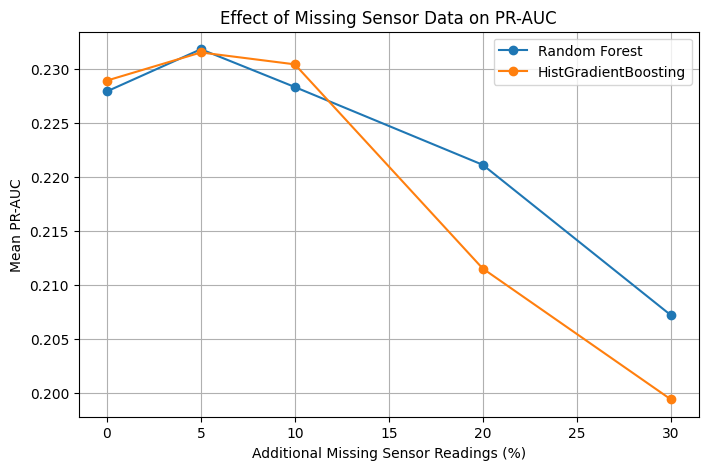

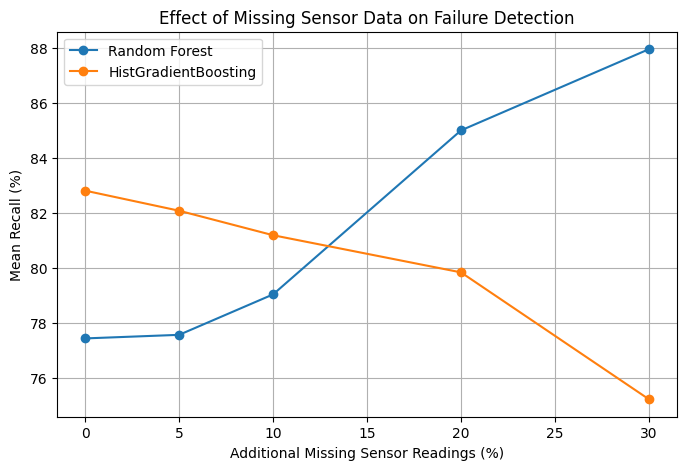

In [46]:
import matplotlib.pyplot as plt

# Separate results for each model
rf_results = summary[
    summary["Model"] == "Random Forest"
]

hgb_results = summary[
    summary["Model"] == "HistGradientBoosting"
]

# Graph 1: PR-AUC
plt.figure(figsize=(8, 5))

plt.plot(
    rf_results["Missingness"] * 100,
    rf_results["PR_AUC_Mean"],
    marker="o",
    label="Random Forest"
)

plt.plot(
    hgb_results["Missingness"] * 100,
    hgb_results["PR_AUC_Mean"],
    marker="o",
    label="HistGradientBoosting"
)

plt.xlabel("Additional Missing Sensor Readings (%)")
plt.ylabel("Mean PR-AUC")
plt.title("Effect of Missing Sensor Data on PR-AUC")
plt.legend()
plt.grid(True)
plt.show()

# Graph 2: Recall
plt.figure(figsize=(8, 5))

plt.plot(
    rf_results["Missingness"] * 100,
    rf_results["Recall_Mean"] * 100,
    marker="o",
    label="Random Forest"
)

plt.plot(
    hgb_results["Missingness"] * 100,
    hgb_results["Recall_Mean"] * 100,
    marker="o",
    label="HistGradientBoosting"
)

plt.xlabel("Additional Missing Sensor Readings (%)")
plt.ylabel("Mean Recall (%)")
plt.title("Effect of Missing Sensor Data on Failure Detection")
plt.legend()
plt.grid(True)
plt.show()

## 5. Chronological evaluation and sensor distribution analysis

In [47]:
# Extract and convert timestamps
timestamps = pd.to_datetime(labels.iloc[:, 1])

# Create a chronological dataset
temporal_data = X.copy()
temporal_data["Target"] = y.values
temporal_data["Timestamp"] = timestamps.values

# Sort observations by time
temporal_data = temporal_data.sort_values(
    "Timestamp"
).reset_index(drop=True)

# Display chronological information
print("TEMPORAL DATASET OVERVIEW")
print("-------------------------")

print("Total observations:", len(temporal_data))
print("Unique timestamps:", temporal_data["Timestamp"].nunique())

print(
    "First observation:",
    temporal_data["Timestamp"].min()
)

print(
    "Last observation:",
    temporal_data["Timestamp"].max()
)

print("\nMonthly failure rates:")

monthly_summary = (
    temporal_data
    .groupby(temporal_data["Timestamp"].dt.month)
    ["Target"]
    .agg(
        Total_Observations="count",
        Failures=lambda x: (x == 1).sum()
    )
)

monthly_summary["Failure_Rate"] = (
    monthly_summary["Failures"]
    / monthly_summary["Total_Observations"]
)

display(monthly_summary.round(4))

TEMPORAL DATASET OVERVIEW
-------------------------
Total observations: 1567
Unique timestamps: 1534
First observation: 2008-07-19 11:55:00
Last observation: 2008-10-17 06:07:00

Monthly failure rates:


/tmp/ipykernel_2589/858035162.py:2: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  timestamps = pd.to_datetime(labels.iloc[:, 1])


,Total_Observations,Failures,Failure_Rate
Timestamp,,,
7,63,14,0.2222
8,555,51,0.0919
9,590,17,0.0288
10,359,22,0.0613


In [48]:
# Correctly parse the original date format
timestamps = pd.to_datetime(
    labels.iloc[:, 1],
    format="%d/%m/%Y %H:%M:%S"
)

# Rebuild the chronological dataset
temporal_data = X.copy()
temporal_data["Target"] = y.values
temporal_data["Timestamp"] = timestamps.values

temporal_data = temporal_data.sort_values(
    "Timestamp"
).reset_index(drop=True)

# Find unique timestamps in chronological order
unique_times = np.sort(
    temporal_data["Timestamp"].unique()
)

# Choose the 70% chronological cutoff
split_position = int(len(unique_times) * 0.70)
cutoff_time = unique_times[split_position]

# Split without separating identical timestamps
train_temporal = temporal_data[
    temporal_data["Timestamp"] < cutoff_time
].copy()

test_temporal = temporal_data[
    temporal_data["Timestamp"] >= cutoff_time
].copy()

# Display split information
print("CHRONOLOGICAL TRAIN-TEST SPLIT")
print("--------------------------------")

print("Cutoff date:", cutoff_time)

print("\nTraining observations:", len(train_temporal))
print("Training failures:", (train_temporal["Target"] == 1).sum())
print(
    "Training period:",
    train_temporal["Timestamp"].min(),
    "to",
    train_temporal["Timestamp"].max()
)

print("\nTesting observations:", len(test_temporal))
print("Testing failures:", (test_temporal["Target"] == 1).sum())
print(
    "Testing period:",
    test_temporal["Timestamp"].min(),
    "to",
    test_temporal["Timestamp"].max()
)

# Confirm that no timestamp is shared between the sets
overlap = set(train_temporal["Timestamp"]) & set(
    test_temporal["Timestamp"]
)

print("\nShared timestamps:", len(overlap))

CHRONOLOGICAL TRAIN-TEST SPLIT
--------------------------------
Cutoff date: 2008-09-26T02:26:00.000000000

Training observations: 1095
Training failures: 78
Training period: 2008-07-19 11:55:00 to 2008-09-26 01:21:00

Testing observations: 472
Testing failures: 26
Testing period: 2008-09-26 02:26:00 to 2008-10-17 06:07:00

Shared timestamps: 0


In [49]:
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# Separate sensor readings and failure labels
X_time = temporal_data[X.columns]
y_time = temporal_data["Target"]
time_values = temporal_data["Timestamp"]

# Use the existing chronological training and testing split
X_train_time = train_temporal[X.columns]
y_train_time = train_temporal["Target"]

X_test_time = test_temporal[X.columns]
y_test_time = test_temporal["Target"]

# Create an earlier training and later validation split
train_times = np.sort(
    train_temporal["Timestamp"].unique()
)

validation_cutoff = train_times[
    int(len(train_times) * 0.80)
]

subtrain_mask = (
    train_temporal["Timestamp"] < validation_cutoff
)

val_mask = ~subtrain_mask

X_subtrain = X_train_time.loc[subtrain_mask]
y_subtrain = y_train_time.loc[subtrain_mask]

X_val = X_train_time.loc[val_mask]
y_val = y_train_time.loc[val_mask]

print("TRAINING AND VALIDATION SETUP")
print("-----------------------------")
print("Subtraining observations:", len(X_subtrain))
print("Validation observations:", len(X_val))
print("Validation failures:", (y_val == 1).sum())

# Train, select threshold, and evaluate each model
temporal_results = []

for model_name in ["Random Forest", "HistGradientBoosting"]:

    model = clone(models[model_name])

    # Train using earlier observations
    model.fit(X_subtrain, y_subtrain)

    positive_index = list(model.classes_).index(1)

    # Predict on the later validation observations
    val_prob = model.predict_proba(X_val)[:, positive_index]

    # Choose the highest threshold achieving at least 80% recall
    thresholds = np.sort(np.unique(val_prob))

    valid_thresholds = [
        t for t in thresholds
        if recall_score(
            y_val,
            np.where(val_prob >= t, 1, -1),
            pos_label=1
        ) >= 0.80
    ]

    selected_threshold = (
        max(valid_thresholds)
        if valid_thresholds
        else thresholds.min()
    )

    # Retrain using the complete chronological training period
    final_model = clone(models[model_name])
    final_model.fit(X_train_time, y_train_time)

    # Evaluate on the untouched later testing period
    test_prob = final_model.predict_proba(
        X_test_time
    )[:, positive_index]

    test_predictions = np.where(
        test_prob >= selected_threshold,
        1,
        -1
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test_time,
        test_predictions,
        labels=[-1, 1]
    ).ravel()

    temporal_results.append({
        "Model": model_name,
        "Threshold": selected_threshold,
        "PR_AUC": average_precision_score(
            y_test_time == 1,
            test_prob
        ),
        "Precision": precision_score(
            y_test_time,
            test_predictions,
            pos_label=1,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_time,
            test_predictions,
            pos_label=1,
            zero_division=0
        ),
        "Inspection_Rate": np.mean(test_predictions == 1),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    })

    print(f"\n{model_name} completed.")
    print("Selected threshold:", round(selected_threshold, 4))

temporal_results_df = pd.DataFrame(temporal_results)

print("\nCHRONOLOGICAL TEST RESULTS")
display(temporal_results_df.round(4))

TRAINING AND VALIDATION SETUP
-----------------------------
Subtraining observations: 878
Validation observations: 217
Validation failures: 6

Random Forest completed.
Selected threshold: 0.0682

HistGradientBoosting completed.
Selected threshold: 0.0061

CHRONOLOGICAL TEST RESULTS


,Model,Threshold,PR_AUC,Precision,Recall,Inspection_Rate,TP,FP,TN,FN
0,Random Forest,0.0682,0.0641,0.0645,0.3077,0.2627,8,116,330,18
1,HistGradientBoosting,0.0061,0.0552,0.0488,0.3846,0.4343,10,195,251,16


### Preliminary Single-Split Chronological Evaluation

A preliminary chronological holdout experiment used earlier observations for model development and a later 30% of observations for testing. It indicated weaker performance than the grouped cross-validation experiments. Because it uses one temporal split and a relatively small number of failure observations, it is treated as an exploratory result. The more informative temporal generalisation analysis is the expanding-window evaluation in Section 7, which tests three successive periods.


In [50]:
# Compare missing sensor readings between periods

train_sensor_data = train_temporal[X.columns]
test_sensor_data = test_temporal[X.columns]

train_missing = train_sensor_data.isna().mean().mean() * 100
test_missing = test_sensor_data.isna().mean().mean() * 100

train_failure_rate = (
    train_temporal["Target"] == 1
).mean() * 100

test_failure_rate = (
    test_temporal["Target"] == 1
).mean() * 100

comparison = pd.DataFrame({
    "Measurement": [
        "Observations",
        "Failure Rate (%)",
        "Missing Sensor Readings (%)"
    ],
    "Earlier Period": [
        len(train_temporal),
        round(train_failure_rate, 2),
        round(train_missing, 2)
    ],
    "Later Period": [
        len(test_temporal),
        round(test_failure_rate, 2),
        round(test_missing, 2)
    ]
})

print("EARLIER VS LATER MANUFACTURING DATA")
display(comparison)

EARLIER VS LATER MANUFACTURING DATA


,Measurement,Earlier Period,Later Period
0,Observations,1095.00,472.00
1,Failure Rate (%),7.12,5.51
2,Missing Sensor Readings (%),4.92,3.64


In [51]:
# Compare sensor reading patterns across time

train_means = train_sensor_data.mean()
test_means = test_sensor_data.mean()

train_stds = train_sensor_data.std()

# Measure how much each sensor's average reading shifted
sensor_shift = (
    (test_means - train_means) / train_stds
).replace([np.inf, -np.inf], np.nan).dropna()

# Summarise the changes
print("SENSOR READING SHIFT ANALYSIS")
print("-----------------------------")

print("Sensors analysed:", len(sensor_shift))

print(
    "Sensors with shift above 1 standard deviation:",
    (sensor_shift.abs() > 1).sum()
)

print(
    "Sensors with shift above 2 standard deviations:",
    (sensor_shift.abs() > 2).sum()
)

print(
    "Average absolute shift:",
    round(sensor_shift.abs().mean(), 4)
)

print(
    "Largest absolute shift:",
    round(sensor_shift.abs().max(), 4)
)

# Display the 10 sensors with the largest shifts
print("\nTOP 10 SENSOR SHIFTS")

display(
    sensor_shift.abs()
    .sort_values(ascending=False)
    .head(10)
    .rename("Absolute_Shift")
    .to_frame()
)

SENSOR READING SHIFT ANALYSIS
-----------------------------
Sensors analysed: 468
Sensors with shift above 1 standard deviation: 13
Sensors with shift above 2 standard deviations: 8
Average absolute shift: 1.3437
Largest absolute shift: 264.5009

TOP 10 SENSOR SHIFTS


,Absolute_Shift
140,264.500927
275,210.128690
4,25.547544
516,3.966791
390,3.951687
252,3.798553
244,3.113769
382,3.091566
112,1.579534
517,1.517845


In [52]:
# Investigate the two sensors with the largest shifts

sensors_to_check = [140, 275]

for sensor in sensors_to_check:

    earlier = train_sensor_data[sensor].dropna()
    later = test_sensor_data[sensor].dropna()

    print(f"\nSENSOR {sensor}")
    print("-" * 35)

    print("Earlier period:")
    print("Available readings:", len(earlier))
    print("Mean:", earlier.mean())
    print("Standard deviation:", earlier.std())
    print("Minimum:", earlier.min())
    print("Maximum:", earlier.max())

    print("\nLater period:")
    print("Available readings:", len(later))
    print("Mean:", later.mean())
    print("Standard deviation:", later.std())
    print("Minimum:", later.min())
    print("Maximum:", later.max())

    print("\nMean difference:", later.mean() - earlier.mean())


SENSOR 140
-----------------------------------
Earlier period:
Available readings: 1089
Mean: 0.3215963269054178
Standard deviation: 0.32591915003236527
Minimum: 0.0319
Maximum: 3.225

Later period:
Available readings: 464
Mean: 86.52751379310344
Standard deviation: 925.2860181566106
Minimum: 0.0522
Maximum: 9998.8944

Mean difference: 86.20591746619802

SENSOR 275
-----------------------------------
Earlier period:
Available readings: 1089
Mean: 0.10934325068870522
Standard deviation: 0.13672603777346923
Minimum: 0.0111
Maximum: 1.5361

Later period:
Available readings: 464
Mean: 28.83940646551724
Standard deviation: 308.3837714446579
Minimum: 0.0192
Maximum: 3332.5964

Mean difference: 28.730063214828533


In [53]:
for sensor in [140, 275]:

    earlier = train_sensor_data[sensor].dropna()
    later = test_sensor_data[sensor].dropna()

    print(f"\nSENSOR {sensor}")
    print("=" * 45)

    print("\nEarlier period distribution:")
    print(earlier.quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]))

    print("\nLater period distribution:")
    print(later.quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]))

    print("\nLater readings above 10:")
    print((later > 10).sum())

    print("Later readings above 100:")
    print((later > 100).sum())

    print("Later readings above 1000:")
    print((later > 1000).sum())


SENSOR 140

Earlier period distribution:
0.00    0.03190
0.25    0.13180
0.50    0.23610
0.75    0.42870
0.90    0.57620
0.95    0.65394
0.99    1.57730
1.00    3.22500
Name: 140, dtype: float64

Later period distribution:
0.00       0.052200
0.25       0.129350
0.50       0.235200
0.75       0.464825
0.90       0.699600
0.95       1.157315
0.99       1.346912
1.00    9998.894400
Name: 140, dtype: float64

Later readings above 10:
4
Later readings above 100:
4
Later readings above 1000:
4

SENSOR 275

Earlier period distribution:
0.00    0.01110
0.25    0.04610
0.50    0.07910
0.75    0.14060
0.90    0.19602
0.95    0.23390
0.99    0.46110
1.00    1.53610
Name: 275, dtype: float64

Later period distribution:
0.00       0.019200
0.25       0.044100
0.50       0.070850
0.75       0.161600
0.90       0.223100
0.95       0.405550
0.99       0.511121
1.00    3332.596400
Name: 275, dtype: float64

Later readings above 10:
4
Later readings above 100:
4
Later readings above 1000:
4


In [54]:
# Compare sensor medians using the earlier period's IQR as the scale.
# IQR = interquartile range (75th percentile - 25th percentile).

train_median = train_sensor_data.median()
test_median = test_sensor_data.median()

train_iqr = (
    train_sensor_data.quantile(0.75)
    - train_sensor_data.quantile(0.25)
)

robust_shift = (
    (test_median - train_median) / train_iqr
).replace([np.inf, -np.inf], np.nan).dropna()

print("Sensors analysed:", len(robust_shift))
print("Sensors with absolute median shift > 1 IQR:",
      (robust_shift.abs() > 1).sum())
print("Sensors with absolute median shift > 2 IQR:",
      (robust_shift.abs() > 2).sum())
print("Average absolute median shift:", robust_shift.abs().mean())

print("\nTop 10 sensors by absolute median shift:")
print(robust_shift.abs().sort_values(ascending=False).head(10))

Sensors analysed: 460
Sensors with absolute median shift > 1 IQR: 6
Sensors with absolute median shift > 2 IQR: 1
Average absolute median shift: 0.2352214384227414

Top 10 sensors by absolute median shift:
116    2.400000
109    1.413793
383    1.256416
245    1.179727
517    1.173310
318    1.057471
95     1.000000
34     0.953368
36     0.953368
28     0.920341
dtype: float64


### Preliminary Single-Split Sensor Distribution Check

An earlier 70/30 chronological holdout analysis compared sensor distributions between one training period and one later test period. This was a preliminary diagnostic, not the final temporal-drift assessment. Its limited single-split design and sensitivity to individual sensors motivated the more detailed expanding-window audit in Section 7. The final interpretation of temporal distribution changes is based on the multi-period analysis reported later in this notebook.


## 6. Five-fold grouped feature-importance analysis

In [55]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# Five-fold grouped validation
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_importances = []
fold_scores = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y, groups=timestamps), start=1
):

    print(f"\nRunning fold {fold}/5...")

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Same Random Forest pipeline as our baseline
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("model", RandomForestClassifier(
            n_estimators=500,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)

    # Fold-level predictive performance
    probabilities = model.predict_proba(X_test)[:, 1]

    ap = average_precision_score(
        (y_test == 1).astype(int),
        probabilities
    )

    fold_scores.append(ap)

    # Permutation importance on unseen test observations
    importance = permutation_importance(
        model,
        X_test,
        (y_test == 1).astype(int),
        scoring="average_precision",
        n_repeats=10,
        random_state=42,
        n_jobs=1
    )

    fold_importances.append(
        pd.Series(
            importance.importances_mean,
            index=X.columns
        )
    )

    print(f"Fold {fold} PR-AUC: {ap:.4f}")

# Combine importance results across folds
importance_df = pd.DataFrame(fold_importances)

summary = pd.DataFrame({
    "Mean_Importance": importance_df.mean(),
    "Std_Importance": importance_df.std(),
    "Top20_Fold_Count": (
        importance_df.rank(axis=1, ascending=False) <= 20
    ).sum()
})

summary = summary.sort_values(
    "Mean_Importance",
    ascending=False
)

print("\nFIVE-FOLD PR-AUC RESULTS:")
print([round(score, 4) for score in fold_scores])

print("\nMean PR-AUC:", round(np.mean(fold_scores), 4))
print("PR-AUC standard deviation:", round(np.std(fold_scores), 4))

print("\nTOP 20 SENSOR FEATURES:")
display(summary.head(20))


Running fold 1/5...
Fold 1 PR-AUC: 0.2436

Running fold 2/5...
Fold 2 PR-AUC: 0.3468

Running fold 3/5...
Fold 3 PR-AUC: 0.1314

Running fold 4/5...
Fold 4 PR-AUC: 0.1238

Running fold 5/5...
Fold 5 PR-AUC: 0.3383

FIVE-FOLD PR-AUC RESULTS:
[np.float64(0.2436), np.float64(0.3468), np.float64(0.1314), np.float64(0.1238), np.float64(0.3383)]

Mean PR-AUC: 0.2368
PR-AUC standard deviation: 0.0963

TOP 20 SENSOR FEATURES:


,Mean_Importance,Std_Importance,Top20_Fold_Count
59,0.003459,0.013925,3
65,0.002537,0.004358,2
31,0.002146,0.011798,1
425,0.001752,0.006242,2
485,0.001446,0.002268,2
152,0.001369,0.003902,3
367,0.000942,0.003136,1
64,0.000934,0.003880,2
484,0.000861,0.004654,2
91,0.000815,0.003857,2


### Grouped permutation-importance findings

Across five grouped folds, the mean baseline PR-AUC was **0.2368 ± 0.0963**. With ten permutation repetitions per feature and fold, Sensor 59 had the highest mean importance (**0.003459**) and was among the top features in three folds. Other relatively high-ranking features included Sensors 65, 31, 425, 485 and 152.

Importance varied across folds, so these rankings should be treated as exploratory predictive associations, not causal evidence or a validated reduced sensor set. Sensor 33 ranked highest in a separate three-repeat run, which is not used as the primary result here.


## 7. Expanding-window temporal validation and drift audit

In [56]:
# LITHOAI 2.0 — Chronological Distribution Audit
# Reuses the dataset loaded in the opening setup cells; no second download is needed.

import numpy as np
import pandas as pd

# Build a timestamp-sorted audit table while preserving identical timestamps.
audit_data = pd.DataFrame({
    "Target": y_binary,
    "Timestamp": timestamps
}).sort_values("Timestamp", kind="stable").reset_index(drop=True)

unique_times = np.sort(audit_data["Timestamp"].unique())
time_blocks = np.array_split(unique_times, 5)

results = []
for i, block in enumerate(time_blocks, start=1):
    block_data = audit_data[audit_data["Timestamp"].isin(block)]
    total = len(block_data)
    failures = int(block_data["Target"].sum())
    results.append({
        "Period": f"Period {i}",
        "Start": block[0],
        "End": block[-1],
        "Observations": total,
        "Failures": failures,
        "Passing": total - failures,
        "Failure_Rate (%)": round(failures / total * 100, 2)
    })

temporal_summary = pd.DataFrame(results)
print("CHRONOLOGICAL DISTRIBUTION AUDIT")
display(temporal_summary)

print("\nDATASET INTEGRITY CHECK")
print("Total observations:", len(audit_data))
print("Total failures:", int(y_binary.sum()))
print("Total non-defective:", int((y_binary == 0).sum()))
print("Unique timestamps:", len(unique_times))
print("Duplicate timestamps:", int(audit_data["Timestamp"].duplicated().sum()))
print("Feature dataset shape:", X.shape)
print("Label dataset shape:", labels.shape)


CHRONOLOGICAL DISTRIBUTION AUDIT


,Period,Start,End,Observations,Failures,Passing,Failure_Rate (%)
0,Period 1,2008-07-19 11:55:00,2008-08-19 15:33:00,311,44,267,14.15
1,Period 2,2008-08-19 18:12:00,2008-09-01 09:06:00,318,21,297,6.60
2,Period 3,2008-09-01 09:19:00,2008-09-20 07:21:00,313,11,302,3.51
3,Period 4,2008-09-20 08:14:00,2008-10-02 17:19:00,309,11,298,3.56
4,Period 5,2008-10-02 19:21:00,2008-10-17 06:07:00,316,17,299,5.38



DATASET INTEGRITY CHECK
Total observations: 1567
Total failures: 104
Total non-defective: 1463
Unique timestamps: 1534
Duplicate timestamps: 33
Feature dataset shape: (1567, 590)
Label dataset shape: (1567, 2)


In [57]:

# LITHOAI 2.0
# STEP 2: Expanding-Window Temporal Validation

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import average_precision_score

# --------------------------------------------------
# 1. PREPARE CHRONOLOGICALLY SORTED DATA
# --------------------------------------------------

time_values = pd.to_datetime(
    labels.iloc[:, 1],
    dayfirst=True
)

target = (labels.iloc[:, 0] == 1).astype(int)

order = np.argsort(time_values.to_numpy(), kind="stable")

X_ordered = X.iloc[order].reset_index(drop=True)
y_ordered = target.iloc[order].reset_index(drop=True)
time_ordered = time_values.iloc[order].reset_index(drop=True)

# Preserve identical timestamps in the same period
unique_times = np.sort(time_ordered.unique())
time_blocks = np.array_split(unique_times, 5)

# --------------------------------------------------
# 2. DEFINE THE ORIGINAL MODEL CONFIGURATIONS
# --------------------------------------------------

models_temporal = {

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )),
        ("variance", VarianceThreshold()),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

# --------------------------------------------------
# 3. RUN EXPANDING-WINDOW EVALUATION
# --------------------------------------------------

results_temporal = []

for test_period in range(2, 5):

    train_times = np.concatenate(
        time_blocks[:test_period]
    )

    test_times = time_blocks[test_period]

    train_mask = time_ordered.isin(train_times)
    test_mask = time_ordered.isin(test_times)

    X_train = X_ordered.loc[train_mask]
    y_train = y_ordered.loc[train_mask]

    X_test = X_ordered.loc[test_mask]
    y_test = y_ordered.loc[test_mask]

    baseline_ap = y_test.mean()

    print("\n" + "=" * 60)
    print(f"TESTING ON PERIOD {test_period + 1}")
    print("=" * 60)

    print("Training observations:", len(X_train))
    print("Training failures:", int(y_train.sum()))

    print("Testing observations:", len(X_test))
    print("Testing failures:", int(y_test.sum()))

    print("Test defect prevalence:", round(baseline_ap, 4))

    for model_name, base_model in models_temporal.items():

        model = clone(base_model)

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_test)[:, 1]

        pr_auc = average_precision_score(
            y_test,
            probabilities
        )

        results_temporal.append({
            "Test_Period": test_period + 1,
            "Model": model_name,
            "Train_Observations": len(X_train),
            "Train_Failures": int(y_train.sum()),
            "Test_Observations": len(X_test),
            "Test_Failures": int(y_test.sum()),
            "Baseline_PR_AUC": baseline_ap,
            "Model_PR_AUC": pr_auc,
            "AP_Lift": pr_auc / baseline_ap
        })

        print(
            f"{model_name}: PR-AUC = {pr_auc:.4f}"
        )

# --------------------------------------------------
# 4. DISPLAY FINAL RESULTS
# --------------------------------------------------

temporal_results = pd.DataFrame(results_temporal)

print("\nEXPANDING-WINDOW VALIDATION RESULTS")
print("=" * 70)

display(temporal_results.round(4))

print("\nMODEL-WISE SUMMARY")

display(
    temporal_results.groupby("Model")[
        ["Model_PR_AUC", "Baseline_PR_AUC"]
    ].mean().round(4)
)



TESTING ON PERIOD 3
Training observations: 629
Training failures: 65
Testing observations: 313
Testing failures: 11
Test defect prevalence: 0.0351


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: [ 85 109 110 111 220 244 245 246 358 382 383 384 492 516 517 518]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: [ 85 109 110 111 220 244 245 246 358 382 383 384 492 516 517 518]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Random Forest: PR-AUC = 0.2795
HistGradientBoosting: PR-AUC = 0.2979

TESTING ON PERIOD 4
Training observations: 942
Training failures: 76
Testing observations: 309
Testing failures: 11
Test defect prevalence: 0.0356
Random Forest: PR-AUC = 0.0579
HistGradientBoosting: PR-AUC = 0.0471

TESTING ON PERIOD 5
Training observations: 1251
Training failures: 87
Testing observations: 316
Testing failures: 17
Test defect prevalence: 0.0538
Random Forest: PR-AUC = 0.0930
HistGradientBoosting: PR-AUC = 0.0543

EXPANDING-WINDOW VALIDATION RESULTS


,Test_Period,Model,Train_Observations,Train_Failures,Test_Observations,Test_Failures,Baseline_PR_AUC,Model_PR_AUC,AP_Lift
0,3,Random Forest,629,65,313,11,0.0351,0.2795,7.9539
1,3,HistGradientBoosting,629,65,313,11,0.0351,0.2979,8.4764
2,4,Random Forest,942,76,309,11,0.0356,0.0579,1.6275
3,4,HistGradientBoosting,942,76,309,11,0.0356,0.0471,1.3232
4,5,Random Forest,1251,87,316,17,0.0538,0.0930,1.7289
5,5,HistGradientBoosting,1251,87,316,17,0.0538,0.0543,1.0089



MODEL-WISE SUMMARY


,Model_PR_AUC,Baseline_PR_AUC
Model,,
HistGradientBoosting,0.1331,0.0415
Random Forest,0.1435,0.0415


In [58]:

# LITHOAI 2.0
# STEP 3: Robust Sensor Distribution Drift Audit

import numpy as np
import pandas as pd

drift_results = []

for test_period in range(2, 5):

    train_times = np.concatenate(time_blocks[:test_period])
    test_times = time_blocks[test_period]

    train_mask = time_ordered.isin(train_times)
    test_mask = time_ordered.isin(test_times)

    X_train = X_ordered.loc[train_mask]
    X_test = X_ordered.loc[test_mask]

    # Missingness comparison
    train_missing = X_train.isna().mean()
    test_missing = X_test.isna().mean()

    # Robust distribution statistics
    train_median = X_train.median()
    test_median = X_test.median()

    train_iqr = (
        X_train.quantile(0.75) -
        X_train.quantile(0.25)
    )

    # Exclude features without a usable training IQR
    valid = (
        train_iqr.notna() &
        (train_iqr > 0) &
        train_median.notna() &
        test_median.notna()
    )

    scaled_shift = (
        (test_median[valid] - train_median[valid]).abs()
        / train_iqr[valid]
    )

    missing_change = (
        test_missing - train_missing
    ).abs()

    drift_results.append({
        "Test_Period": test_period + 1,
        "Sensors_Analysed": int(valid.sum()),
        "Sensors_All_Missing_In_Train": int(
            X_train.isna().all().sum()
        ),
        "Median_Shift_Above_1_IQR": int(
            (scaled_shift > 1).sum()
        ),
        "Median_Shift_Above_2_IQR": int(
            (scaled_shift > 2).sum()
        ),
        "Mean_Absolute_Median_Shift_IQR": round(
            scaled_shift.mean(), 4
        ),
        "Sensors_Missingness_Change_Above_10pp": int(
            (missing_change > 0.10).sum()
        ),
        "Mean_Missingness_Change": round(
            missing_change.mean(), 4
        )
    })

drift_summary = pd.DataFrame(drift_results)

print("ROBUST SENSOR DRIFT AUDIT")
print("=" * 75)

display(drift_summary)


ROBUST SENSOR DRIFT AUDIT


,Test_Period,Sensors_Analysed,Sensors_All_Missing_In_Train,Median_Shift_Above_1_IQR,Median_Shift_Above_2_IQR,Mean_Absolute_Median_Shift_IQR,Sensors_Missingness_Change_Above_10pp,Mean_Missingness_Change
0,3,444,16,1,0,0.1787,36,0.0189
1,4,460,0,7,1,0.2213,44,0.0276
2,5,464,0,9,5,0.2842,56,0.0377


In [59]:

# LITHOAI 2.0
# STEP 4: Identify Sensors Showing the Largest Temporal Changes

sensor_shift_tables = {}

for test_period in range(2, 5):

    train_times = np.concatenate(time_blocks[:test_period])
    test_times = time_blocks[test_period]

    train_mask = time_ordered.isin(train_times)
    test_mask = time_ordered.isin(test_times)

    X_train = X_ordered.loc[train_mask]
    X_test = X_ordered.loc[test_mask]

    train_median = X_train.median()
    test_median = X_test.median()

    train_iqr = (
        X_train.quantile(0.75) -
        X_train.quantile(0.25)
    )

    valid = (
        train_iqr.notna() &
        (train_iqr > 0) &
        train_median.notna() &
        test_median.notna()
    )

    median_shift = (
        (test_median[valid] - train_median[valid]).abs()
        / train_iqr[valid]
    )

    missingness_change = (
        X_test.isna().mean() -
        X_train.isna().mean()
    )

    sensor_table = pd.DataFrame({
        "Sensor": X.columns[valid],
        "Median_Shift_IQR": median_shift.values,
        "Missingness_Change_pp": (
            missingness_change.loc[valid].values * 100
        )
    })

    sensor_table["Absolute_Missingness_Change_pp"] = (
        sensor_table["Missingness_Change_pp"].abs()
    )

    sensor_shift_tables[test_period + 1] = sensor_table

    print(f"\nTOP 15 SENSOR SHIFTS: PERIOD {test_period + 1}")
    display(
        sensor_table.sort_values(
            "Median_Shift_IQR",
            ascending=False
        ).head(15).round(3)
    )

    print(f"\nTOP 15 MISSINGNESS CHANGES: PERIOD {test_period + 1}")
    display(
        sensor_table.sort_values(
            "Absolute_Missingness_Change_pp",
            ascending=False
        ).head(15).round(3)
    )



TOP 15 SENSOR SHIFTS: PERIOD 3


,Sensor,Median_Shift_IQR,Missingness_Change_pp,Absolute_Missingness_Change_pp
71,78,1.081,0.000,0.000
375,487,0.921,0.000,0.000
26,28,0.868,0.161,0.161
41,44,0.662,-0.159,0.159
358,468,0.651,0.321,0.321
202,239,0.643,0.000,0.000
73,80,0.631,0.000,0.000
328,428,0.616,-1.111,1.111
140,155,0.602,-1.111,1.111
338,438,0.566,0.161,0.161



TOP 15 MISSINGNESS CHANGES: PERIOD 3


,Sensor,Median_Shift_IQR,Missingness_Change_pp,Absolute_Missingness_Change_pp
67,73,0.052,29.544,29.544
66,72,0.032,29.544,29.544
276,345,0.177,29.544,29.544
277,346,0.161,29.544,29.544
416,562,0.017,-23.470,23.470
417,563,0.075,-23.470,23.470
419,565,0.155,-23.470,23.470
418,564,0.109,-23.470,23.470
423,569,0.277,-23.470,23.470
422,568,0.075,-23.470,23.470



TOP 15 SENSOR SHIFTS: PERIOD 4


,Sensor,Median_Shift_IQR,Missingness_Change_pp,Absolute_Missingness_Change_pp
120,129,4.580,-0.637,0.637
101,109,1.146,-55.909,55.909
318,393,1.133,0.000,0.000
103,111,1.041,-55.909,55.909
412,527,1.030,0.000,0.000
71,78,1.026,0.000,0.000
218,255,1.022,0.000,0.000
88,95,1.000,0.223,0.223
265,318,0.895,-0.106,0.106
32,34,0.800,-0.106,0.106


... (2 outputs left out)


TOP 15 SENSOR SHIFTS: PERIOD 5


,Sensor,Median_Shift_IQR,Missingness_Change_pp,Absolute_Missingness_Change_pp
419,545,7.847,0.633,0.633
417,543,6.000,0.633,0.633
416,542,2.500,0.633,0.633
107,116,2.167,0.000,0.000
418,544,2.000,0.633,0.633
103,111,1.721,-63.141,63.141
309,383,1.553,-63.141,63.141
403,517,1.489,-63.141,63.141
209,245,1.372,-63.141,63.141
88,95,1.000,-0.480,0.480



TOP 15 MISSINGNESS CHANGES: PERIOD 5


,Sensor,Median_Shift_IQR,Missingness_Change_pp,Absolute_Missingness_Change_pp
404,518,0.024,-63.141,63.141
402,516,0.361,-63.141,63.141
403,517,1.489,-63.141,63.141
103,111,1.721,-63.141,63.141
308,382,0.333,-63.141,63.141
102,110,0.547,-63.141,63.141
209,245,1.372,-63.141,63.141
208,244,0.353,-63.141,63.141
310,384,0.094,-63.141,63.141
309,383,1.553,-63.141,63.141


In [60]:

# LITHOAI 2.0
# STEP 5: Inspect Raw Distributions of Potentially Unstable Sensors

selected_sensors = [
    72, 73, 78, 95,
    109, 110, 111, 112, 116, 129,
    244, 245, 246, 247,
    316, 318, 345, 346,
    382, 383, 384, 385,
    487,
    516, 517, 518, 519,
    542, 543, 544, 545
]

distribution_records = []

for test_period in range(2, 5):

    train_times = np.concatenate(time_blocks[:test_period])
    test_times = time_blocks[test_period]

    train_mask = time_ordered.isin(train_times)
    test_mask = time_ordered.isin(test_times)

    for sensor in selected_sensors:

        for split_name, data in [
            ("Train", X_ordered.loc[train_mask]),
            ("Test", X_ordered.loc[test_mask])
        ]:

            values = data[sensor].dropna()

            distribution_records.append({
                "Test_Period": test_period + 1,
                "Sensor": sensor,
                "Split": split_name,
                "Observed_Count": len(values),
                "Missing_Percent": round(
                    data[sensor].isna().mean() * 100, 2
                ),
                "Median": values.median() if len(values) else np.nan,
                "Q25": values.quantile(0.25) if len(values) else np.nan,
                "Q75": values.quantile(0.75) if len(values) else np.nan,
                "IQR": (
                    values.quantile(0.75) -
                    values.quantile(0.25)
                ) if len(values) else np.nan
            })

distribution_audit = pd.DataFrame(distribution_records)

for period in [3, 4, 5]:

    print(f"\nRAW SENSOR DISTRIBUTIONS: PERIOD {period}")
    display(
        distribution_audit[
            distribution_audit["Test_Period"] == period
        ].round(4)
    )



RAW SENSOR DISTRIBUTIONS: PERIOD 3


,Test_Period,Sensor,Split,Observed_Count,Missing_Percent,Median,Q25,Q75,IQR
0,3,72,Train,431,31.48,149.5895,141.9098,157.7840,15.8742
1,3,72,Test,122,61.02,150.0956,145.0244,155.0931,10.0687
2,3,73,Train,431,31.48,466.5214,464.6398,468.3602,3.7203
3,3,73,Test,122,61.02,466.7150,464.6363,468.1216,3.4852
4,3,78,Train,629,0.00,-0.0509,-0.0710,-0.0288,0.0422
...,...,...,...,...,...,...,...,...,...
57,3,543,Test,313,0.00,0.0078,0.0078,0.0088,0.0010
58,3,544,Train,629,0.00,0.0026,0.0026,0.0026,0.0000
59,3,544,Test,313,0.00,0.0026,0.0023,0.0026,0.0003
60,3,545,Train,629,0.00,7.1160,7.1160,7.1160,0.0000



RAW SENSOR DISTRIBUTIONS: PERIOD 4


,Test_Period,Sensor,Split,Observed_Count,Missing_Percent,Median,Q25,Q75,IQR
62,4,72,Train,553,41.30,149.6372,142.9333,157.0290,14.0957
63,4,72,Test,124,59.87,154.0468,150.1091,157.9621,7.8530
64,4,73,Train,553,41.30,466.5644,464.6345,468.3273,3.6928
65,4,73,Test,124,59.87,465.3932,463.6472,466.5910,2.9438
66,4,78,Train,942,0.00,-0.0372,-0.0642,-0.0103,0.0540
...,...,...,...,...,...,...,...,...,...
119,4,543,Test,309,0.00,0.0090,0.0078,0.0103,0.0025
120,4,544,Train,942,0.00,0.0026,0.0026,0.0026,0.0000
121,4,544,Test,309,0.00,0.0024,0.0021,0.0027,0.0006
122,4,545,Train,942,0.00,7.1160,7.1160,7.1160,0.0000



RAW SENSOR DISTRIBUTIONS: PERIOD 5


,Test_Period,Sensor,Split,Observed_Count,Missing_Percent,Median,Q25,Q75,IQR
124,5,72,Train,677,45.88,151.0837,143.9415,157.4114,13.4699
125,5,72,Test,96,69.62,158.0564,155.2300,164.9856,9.7555
126,5,73,Train,677,45.88,466.2314,464.4555,468.0159,3.5604
127,5,73,Test,96,69.62,465.6925,464.5294,466.8919,2.3625
128,5,78,Train,1251,0.00,-0.0232,-0.0550,0.0104,0.0653
...,...,...,...,...,...,...,...,...,...
181,5,543,Test,314,0.63,0.0093,0.0079,0.0104,0.0025
182,5,544,Train,1251,0.00,0.0026,0.0025,0.0026,0.0001
183,5,544,Test,314,0.63,0.0024,0.0022,0.0027,0.0005
184,5,545,Train,1251,0.00,7.1160,7.1160,7.2570,0.1410


In [61]:
focus_sensors = [
    72, 73, 78,
    109, 111, 383, 517,
    542, 543, 544, 545
]

focused_audit = distribution_audit[
    distribution_audit["Sensor"].isin(focus_sensors)
].copy()

focused_audit = focused_audit.sort_values(
    ["Sensor", "Test_Period", "Split"]
)

display(focused_audit.round(4).to_string(index=False))

' Test_Period  Sensor Split  Observed_Count  Missing_Percent   Median      Q25      Q75     IQR\n           3      72  Test             122            61.02 150.0956 145.0244 155.0931 10.0687\n           3      72 Train             431            31.48 149.5895 141.9098 157.7840 15.8742\n           4      72  Test             124            59.87 154.0468 150.1091 157.9621  7.8530\n           4      72 Train             553            41.30 149.6372 142.9333 157.0290 14.0957\n           5      72  Test              96            69.62 158.0564 155.2300 164.9856  9.7555\n           5      72 Train             677            45.88 151.0837 143.9415 157.4114 13.4699\n           3      73  Test             122            61.02 466.7150 464.6363 468.1216  3.4852\n           3      73 Train             431            31.48 466.5214 464.6398 468.3602  3.7203\n           4      73  Test             124            59.87 465.3932 463.6472 466.5910  2.9438\n           4      73 Train             

Sensor-level distribution analysis
The sensor-level audit was conducted to examine whether the changes observed across chronological test periods were associated with differences in individual sensor distributions. Sensor 72 showed a progressive increase in its median value across the later test periods: from 149.59 in the training data to 150.10 in Period 3, 154.05 in Period 4, and 158.06 in Period 5. However, its missingness also increased considerably, reaching 69.62% in the Period 5 test set compared with 45.88% in the corresponding training data. This means that the observed median shift may partly reflect a change in which sensor readings were available. Sensor 73, in comparison, showed relatively smaller median changes despite following a similar missingness pattern.

Sensor 545 showed another notable distribution change. In Period 3, its training and test medians were both 7.116, but the test distribution had a wider interquartile range. In Period 5, its median increased from 7.116 in training to 8.222 in testing, accompanied by a substantial increase in spread. The broader audit also identified recurring missingness changes across groups of sensors, particularly around sensor indices 109–112, 244–247, 382–385, and 516–519. These observations suggest that the dataset contains both missingness-pattern changes and shifts in the distributions of certain observed sensor readings. However, this analysis alone cannot establish that these changes caused the decline in predictive performance. Further investigation would be required to determine their relationship with model generalisation.

In [62]:
import pandas as pd
import numpy as np

# Separate training and testing statistics
train_stats = distribution_audit[
    distribution_audit["Split"] == "Train"
].copy()

test_stats = distribution_audit[
    distribution_audit["Split"] == "Test"
].copy()

# Match each sensor within each test period
comparison = train_stats.merge(
    test_stats,
    on=["Test_Period", "Sensor"],
    suffixes=("_Train", "_Test")
)

# Calculate changes between training and testing
comparison["Median_Shift"] = (
    comparison["Median_Test"] -
    comparison["Median_Train"]
)

comparison["Absolute_Median_Shift"] = (
    comparison["Median_Shift"].abs()
)

# Standardise median shift using training IQR
valid_iqr = comparison["IQR_Train"].where(
    comparison["IQR_Train"] > 0
)
comparison["Standardised_Median_Shift"] = (
    comparison["Absolute_Median_Shift"] / valid_iqr
)

# Calculate missingness change in percentage points
comparison["Missingness_Change_pp"] = (
    comparison["Missing_Percent_Test"] -
    comparison["Missing_Percent_Train"]
)

# Calculate change in distribution spread
comparison["IQR_Change"] = (
    comparison["IQR_Test"] -
    comparison["IQR_Train"]
)

# Select useful columns
sensor_shift_summary = comparison[[
    "Test_Period",
    "Sensor",
    "Observed_Count_Train",
    "Observed_Count_Test",
    "Missingness_Change_pp",
    "Median_Shift",
    "Standardised_Median_Shift",
    "IQR_Change"
]].copy()

# Rank sensors by standardised median shift
sensor_shift_summary = sensor_shift_summary.sort_values(
    ["Test_Period", "Standardised_Median_Shift"],
    ascending=[True, False]
)

print("CONSOLIDATED SENSOR SHIFT ANALYSIS")
display(sensor_shift_summary.round(4))

CONSOLIDATED SENSOR SHIFT ANALYSIS


,Test_Period,Sensor,Observed_Count_Train,Observed_Count_Test,Missingness_Change_pp,Median_Shift,Standardised_Median_Shift,IQR_Change
2,3,78,629,313,0.00,0.0456,1.0806,0.0161
22,3,487,629,313,0.00,57.8069,0.9212,341.5108
3,3,95,629,309,1.28,-0.0001,0.5000,-0.0002
7,3,112,508,202,16.22,-0.0031,0.4120,-0.0019
8,3,116,629,313,0.00,0.0002,0.3333,-0.0001
...,...,...,...,...,...,...,...,...
83,5,385,830,22,59.39,-0.0009,0.1532,-0.0031
63,5,73,677,96,23.74,-0.5389,0.1514,-1.1979
82,5,384,279,270,-63.14,0.0472,0.0936,0.1094
87,5,518,279,270,-63.14,-0.0166,0.0244,0.1733


## 8. Missingness-indicator comparison

In [63]:

# LITHOAI 2.0 — STEP 6
# Missingness Indicator Experiment

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

# Verify restored variables
assert len(X) == len(y_binary) == len(timestamps)

# Chronological ordering
order = np.argsort(timestamps.to_numpy(), kind="stable")

X_time = X.iloc[order].reset_index(drop=True)
y_time = y_binary.iloc[order].reset_index(drop=True)
time_sorted = timestamps.iloc[order].reset_index(drop=True)

# Divide unique timestamps into five periods
unique_times = np.sort(time_sorted.unique())
period_groups = np.array_split(unique_times, 5)

period_indices = {
    i: np.flatnonzero(time_sorted.isin(period).to_numpy())
    for i, period in enumerate(period_groups, start=1)
}

results = []

for test_period in [3, 4, 5]:

    train_idx = np.concatenate([
        period_indices[p]
        for p in range(1, test_period)
    ])

    test_idx = period_indices[test_period]

    X_train, X_test = (
        X_time.iloc[train_idx],
        X_time.iloc[test_idx]
    )

    y_train, y_test = (
        y_time.iloc[train_idx],
        y_time.iloc[test_idx]
    )

    for indicators in [False, True]:

        model = Pipeline([
            ("imputer", SimpleImputer(
                strategy="median",
                add_indicator=indicators,
                keep_empty_features=True
            )),
            ("variance", VarianceThreshold()),
            ("classifier", RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            ))
        ])

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_test)[:, 1]

        ap = average_precision_score(y_test, probabilities)

        results.append({
            "Period": test_period,
            "Indicators": indicators,
            "Failures": int(y_test.sum()),
            "Baseline_AP": round(y_test.mean(), 4),
            "PR_AUC": round(ap, 4)
        })

results_df = pd.DataFrame(results)

print("\nMISSINGNESS INDICATOR EXPERIMENT")
print(results_df.to_string(index=False))

print("\nPERFORMANCE DIFFERENCE (WITH - WITHOUT INDICATORS)")

for period in [3, 4, 5]:
    subset = results_df[results_df["Period"] == period]
    scores = subset.set_index("Indicators")["PR_AUC"]

    print(
        f"Period {period}: "
        f"{scores[True] - scores[False]:+.4f}"
    )




MISSINGNESS INDICATOR EXPERIMENT
 Period  Indicators  Failures  Baseline_AP  PR_AUC
      3       False        11       0.0351  0.2795
      3        True        11       0.0351  0.2489
      4       False        11       0.0356  0.0579
      4        True        11       0.0356  0.0607
      5       False        17       0.0538  0.0930
      5        True        17       0.0538  0.0895

PERFORMANCE DIFFERENCE (WITH - WITHOUT INDICATORS)
Period 3: -0.0306
Period 4: +0.0028
Period 5: -0.0035


## 9. Results and Discussion

### 9.1 Dataset characteristics

The UCI SECOM dataset contains 1,567 manufacturing observations and 590 sensor features. There are 104 failure observations and 1,463 passing observations, giving a failure prevalence of 6.64%. The timestamp column contains 1,534 unique timestamps, so some observations share identical timestamps. Timestamp groups were therefore kept intact during grouped cross-validation to reduce the risk of information leakage between folds. The dataset also contains substantial missing sensor data and a large number of features with limited or no variation, making preprocessing and data availability important parts of the evaluation.

### 9.2 Grouped model comparison

Three models were compared using five-fold StratifiedGroupKFold validation with timestamp groups: Logistic Regression, Random Forest and HistGradientBoosting. Average precision (AP), also referred to here as PR-AUC, was used because the positive class is rare. The pooled out-of-fold AP scores were 0.1390 for Logistic Regression, 0.1860 for Random Forest and 0.1916 for HistGradientBoosting. All three exceeded the overall failure prevalence baseline of 0.0664, while the two tree-based models performed similarly and outperformed the linear baseline in this evaluation.

The fold-level results showed meaningful variability. The mean fold AP was 0.2289 ± 0.0997 for HistGradientBoosting and 0.2279 ± 0.0973 for Random Forest. The pooled AP and mean fold AP are different summaries: pooled AP is calculated once from all out-of-fold predictions, whereas the fold mean averages the five separate fold scores. They should not be treated as interchangeable. The variability across folds indicates that performance depends on the particular grouped split and that a small difference in pooled AP does not establish a consistently superior model.

### 9.3 Nested threshold evaluation and inspection trade-off

Nested grouped validation used five outer folds and four inner folds. Within each outer training set, an operating threshold was selected from inner out-of-fold predictions to target at least 80% recall; that threshold was then evaluated on the untouched outer fold. The target is an evaluation preference, not a guarantee that the same recall will be achieved on unseen observations.

Random Forest achieved pooled recall of 76.92%, precision of 11.19% and an inspection rate of 45.63% (80 true positives, 635 false positives, 828 true negatives and 24 false negatives). HistGradientBoosting achieved pooled recall of 82.69%, precision of 9.46% and an inspection rate of 58.01% (86 true positives, 823 false positives, 640 true negatives and 18 false negatives). Thus, HistGradientBoosting detected six more failures but required 194 additional inspections and generated more false alarms. Neither model dominates across recall, precision and inspection workload. The low precision values show that a substantial proportion of flagged observations were not failures; the models should therefore be interpreted as candidate screening tools rather than definitive defect classifiers.

The thresholds selected in the inner folds differed between models and folds. This is expected because their score distributions differ. The results also show why threshold selection must be separated from outer-fold evaluation: an inner validation target does not ensure the same recall on the held-out fold.

### 9.4 Robustness to additional missing sensor readings

A controlled missing-data experiment introduced additional missingness among readings that were originally observed, while retaining the dataset's original missing values. This simulates inference-time sensor dropout; it does not represent retraining on progressively more incomplete training data.

For HistGradientBoosting, mean AP decreased from 0.2289 at 0% additional missingness to 0.1994 at 30%. Mean recall decreased from 0.8282 to 0.7524, while mean inspection rate changed from 0.5803 to 0.5047. For Random Forest, mean AP decreased from 0.2279 to 0.2072. Its mean recall increased from 0.7745 to 0.8796, but its mean inspection rate also increased from 0.4566 to 0.6438. The increase in Random Forest recall therefore came with a higher inspection burden and should not be interpreted as improved overall robustness. Small non-monotonic changes at intermediate missingness levels are present, so the results are best described as model-specific sensitivity rather than a perfectly monotonic response.

### 9.5 Expanding-window temporal generalisation

To examine performance on later observations, unique timestamps were divided into five chronological periods. Models were trained on all preceding periods and evaluated on the next period, with the same timestamp kept within a single period. The evaluation covered Periods 3, 4 and 5.

For Period 3 (313 test observations, 11 failures), Random Forest achieved AP 0.2795 and HistGradientBoosting achieved AP 0.2979. Performance declined substantially in Period 4 (309 observations, 11 failures): AP was 0.0579 for Random Forest and 0.0471 for HistGradientBoosting. In Period 5 (316 observations, 17 failures), AP was 0.0930 for Random Forest and 0.0543 for HistGradientBoosting. The mean AP across the three test periods was 0.1435 for Random Forest and 0.1331 for HistGradientBoosting; the corresponding mean period-specific prevalence baseline was 0.0415.

These results indicate substantial variation in temporal performance and weaker results in the later two test periods than in Period 3. However, each period contains only 11–17 failures, so the period-specific AP estimates are sensitive to a small number of observations. The experiment provides evidence of limited temporal generalisation on this dataset; it does not identify the cause of the decline or establish that sensor drift caused it.

### 9.6 Sensor distribution and missingness audit

A robust sensor audit compared training and testing distributions in each expanding-window split. Median shifts were scaled by the training interquartile range (IQR), and features without a valid positive training IQR were excluded from the standardised median-shift calculation. The number of sensors with median shifts greater than one training IQR increased from 1 in Period 3 to 7 in Period 4 and 9 in Period 5. The number with shifts greater than two IQRs was 0, 1 and 5, respectively. The number of sensors whose missingness changed by more than 10 percentage points increased from 36 to 44 to 56 across the same periods.

The consolidated sensor-level audit identified notable changes in individual sensors, including Sensor 129 in Period 4 and Sensors 545, 543 and 542 in Period 5. It also identified substantial changes in missingness for groups of sensors, including indices around 109–112, 244–247, 382–385 and 516–519. Some sensors had no observed training readings in an earlier period, so a median shift could not be calculated for them; these cases are reported as unavailable rather than assigned an infinite shift. Distributional changes and missingness changes are descriptive evidence of temporal instability. They do not, by themselves, demonstrate a causal relationship with model performance.

### 9.7 Grouped permutation importance

Grouped permutation importance was estimated across five timestamp-grouped folds using average precision as the scoring metric. The mean fold AP for this feature-importance experiment was 0.2368 ± 0.0963. Sensor 59 had the largest mean permutation importance (0.003459) and appeared among the top 20 features in three folds. Sensors 65, 31, 425, 485 and 152 were also among the higher-ranked features.

The importance values were small and varied across folds. Correlated sensor features can share predictive information, which can reduce or redistribute individual permutation-importance scores. These results are exploratory indicators of predictive association, not evidence that a sensor causes failures, and they do not establish a validated reduced sensor set.

### 9.8 Missingness-indicator experiment

A separate chronological experiment compared Random Forest models with and without missingness indicators. The AP scores without versus with indicators were 0.2795 versus 0.2489 in Period 3, 0.0579 versus 0.0607 in Period 4, and 0.0930 versus 0.0895 in Period 5. The differences were therefore -0.0306, +0.0028 and -0.0035, respectively. Missingness indicators did not produce a consistent improvement across the three periods. Given the small number of failures in each period, these results should be interpreted as a limited comparison rather than a universal conclusion about the usefulness of missingness indicators.

### 9.9 Overall interpretation

The experiments show that grouped validation is essential for this dataset and that Random Forest and HistGradientBoosting provide modest ranking performance above the failure-prevalence baseline. Threshold-based evaluation exposes a practical trade-off between failure coverage and inspection workload. Controlled missingness, expanding-window validation and sensor audits further show that model behaviour can vary as data availability and observation time change. The most important conclusion is not that a production-ready defect predictor has been achieved, but that a reproducible evaluation framework can reveal where apparent performance is fragile and what must be tested before operational use.

## 10. Limitations

1. **Small positive class:** Only 104 of 1,567 observations are failures. The chronological test periods contain just 11, 11 and 17 failures, respectively, making period-specific metrics uncertain.
2. **Single dataset:** The study uses one public dataset. Results may not generalise to other fabrication facilities, tools, process steps or time periods.
3. **Dataset context:** SECOM is a semiconductor manufacturing dataset, but the available records do not establish that the measured variables correspond specifically to a lithography process step. The project title should not be taken as evidence of a lithography-specific deployment.
4. **Temporal evaluation scope:** Expanding-window validation tests three later periods within the same dataset. It is not an external validation on a separate manufacturing line or facility.
5. **Threshold dependence:** Operating thresholds were selected to target an illustrative recall level. Real deployment would require cost-sensitive threshold selection based on inspection capacity, the relative cost of missed failures and false alarms, and prospective validation.
6. **Missing-data simulation:** Artificial masking approximates additional sensor dropout but may not reproduce the mechanisms or correlations that cause real sensor readings to be missing.
7. **Interpretability:** Permutation importance can be affected by correlated features and should not be interpreted causally.
8. **No production validation:** The study does not include real-time integration, process-control feedback, economic evaluation or validation under production constraints. No claim of production readiness is made.

## 11. Conclusion

This study developed and evaluated a machine-learning workflow for semiconductor manufacturing defect prediction using the UCI SECOM dataset. Timestamp-grouped validation showed that Random Forest and HistGradientBoosting achieved pooled average-precision scores of 0.1860 and 0.1916, respectively, compared with 0.1390 for Logistic Regression. Nested threshold evaluation highlighted a trade-off: HistGradientBoosting achieved higher pooled recall (82.69%) but a higher inspection rate (58.01%), while Random Forest achieved 76.92% recall with a 45.63% inspection rate.

Further experiments revealed sensitivity to additional missing sensor readings, substantial variation in later chronological test periods, and changes in both sensor distributions and missingness patterns. Missingness indicators did not consistently improve temporal AP, while grouped permutation importance identified a small set of features with modest and fold-dependent predictive contributions. Taken together, the findings emphasise that grouped validation, temporal testing, missing-data analysis and operational metrics are all necessary when assessing predictive monitoring methods for imbalanced manufacturing data.

The work is a research prototype and methodological investigation, not a validated production system. Future work should evaluate the framework on additional manufacturing datasets, investigate process-aware temporal shifts, assess calibration and uncertainty, and conduct prospective validation using operationally meaningful inspection costs.

## 12. Reproducibility and data source

The experiments use the publicly available UCI SECOM dataset: https://archive.ics.uci.edu/dataset/179/secom. The notebook downloads the dataset from the UCI repository at the start of execution. The main model experiments use fixed random seeds as specified in their code. To reproduce the analysis, run the notebook in a fresh Google Colab runtime from the first cell to the last, with an active internet connection for dataset retrieval. Confirm that all cells complete and that the resulting tables match the reported values before circulating the notebook or citing the numerical results in an application.

**Reporting note:** Average precision is used as the scalar summary of the precision–recall curve and is labelled PR-AUC in the notebook for consistency. The study reports exploratory model comparisons and does not claim causal findings, production readiness or external generalisation.
